# FlowerVision: Flower Image Classification

## Project Overview

FlowerVision is an image classification project that uses machine learning to identify flower species from photographs. The project uses a real-world image dataset containing five flower categories: daisy, dandelion, roses, sunflowers, and tulips.

The goal is to build an end-to-end machine learning pipeline that includes data acquisition, exploratory data analysis, image preprocessing, model development, training, evaluation, predictions, model persistence, and deployment.

The trained model will be integrated into an API and a web dashboard that allows users to upload flower images and receive predictions.

## Objectives

- Explore and visualize the flower image dataset.
- Develop an image preprocessing pipeline.
- Build and train a Convolutional Neural Network (CNN).
- Evaluate the model using multiple classification metrics.
- Support individual image predictions and batch predictions.
- Enable model retraining.
- Deploy the model through an API and web interface.
- Evaluate the system under different request loads.

## Dataset

**Dataset:** TensorFlow Flowers (Flower Photos)

**Classes:** Daisy, Dandelion, Roses, Sunflowers, Tulips

**Total images:** 3,670

**Source:** TensorFlow's publicly available flower photography dataset.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Project Directory Setup

We will store all project files in Google Drive to ensure our work persists beyond temporary Colab sessions. The project directory will contain separate folders for the dataset, notebooks, trained models, application source code, and results.

In [2]:
import os

PROJECT_PATH = "/content/drive/MyDrive/ML_Assignment/FlowerVision"

DATA_DIR = os.path.join(PROJECT_PATH, "data")
RAW_DATA_DIR = os.path.join(DATA_DIR, "raw")
SPLIT_DATA_DIR = os.path.join(DATA_DIR, "splits")

NOTEBOOK_DIR = os.path.join(PROJECT_PATH, "notebook")
MODELS_DIR = os.path.join(PROJECT_PATH, "models")
SRC_DIR = os.path.join(PROJECT_PATH, "src")
RESULTS_DIR = os.path.join(PROJECT_PATH, "results")

folders = [
    RAW_DATA_DIR,
    SPLIT_DATA_DIR,
    NOTEBOOK_DIR,
    MODELS_DIR,
    SRC_DIR,
    RESULTS_DIR
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("FlowerVision project structure created successfully!")
print(f"\nProject location: {PROJECT_PATH}")

for folder in folders:
    print(folder)

FlowerVision project structure created successfully!

Project location: /content/drive/MyDrive/ML_Assignment/FlowerVision
/content/drive/MyDrive/ML_Assignment/FlowerVision/data/raw
/content/drive/MyDrive/ML_Assignment/FlowerVision/data/splits
/content/drive/MyDrive/ML_Assignment/FlowerVision/notebook
/content/drive/MyDrive/ML_Assignment/FlowerVision/models
/content/drive/MyDrive/ML_Assignment/FlowerVision/src
/content/drive/MyDrive/ML_Assignment/FlowerVision/results


## Dataset Acquisition

FlowerVision uses the TensorFlow Flower Photos dataset, a publicly available collection of real flower photographs organized into five categories. The original archive is retained in Google Drive so that the data can be reused without downloading it again every time the Colab runtime restarts.

The dataset will be extracted into the project directory for subsequent exploration, preprocessing, and model development.

In [ ]:
import tarfile
import os

print("Resuming flower dataset extraction...")

with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
    members = tar.getmembers()

    total = len(members)
    extracted = 0

    for i, member in enumerate(members, 1):
        target_path = os.path.join(RAW_DATA_DIR, member.name)

        # Skip files that have already been extracted
        if os.path.exists(target_path):
            continue

        tar.extract(member, path=RAW_DATA_DIR)
        extracted += 1

        if i % 100 == 0:
            print(f"Checked {i}/{total} files")

print(f"\nExtraction complete!")
print(f"New files extracted: {extracted}")
print(f"Dataset location: {EXTRACT_DIR}")

Resuming flower dataset extraction...


/tmp/ipykernel_370/3785738827.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=RAW_DATA_DIR)


Checked 2600/3677 files
Checked 2700/3677 files
Checked 2800/3677 files
Checked 2900/3677 files
Checked 3000/3677 files
Checked 3100/3677 files
Checked 3200/3677 files
Checked 3300/3677 files
Checked 3400/3677 files
Checked 3500/3677 files
Checked 3600/3677 files

Extraction complete!
New files extracted: 1170
Dataset location: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/raw/flower_photos


## Dataset Verification

After extraction, the dataset is inspected to confirm that all expected class directories exist and that the images are accessible. We calculate the number of images in each class, verify the total dataset size, and check for missing or unreadable image files.

This step ensures that the dataset is suitable for subsequent exploratory analysis and model development.

Before training the model, the flower dataset is inspected to confirm that all five target classes are present and that the images can be read successfully.

The dataset contains five flower categories: daisy, dandelion, roses, sunflowers, and tulips.

This step checks:
- The number of images available in each class.
- Whether any classes are missing.
- Whether any images are corrupted or unreadable.

These checks help ensure that the dataset is complete and suitable for model development.


In [4]:
from pathlib import Path
from PIL import Image
from collections import Counter

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

class_counts = {}
corrupted_images = []
missing_classes = []

for class_name in CLASS_NAMES:
    class_dir = os.path.join(EXTRACT_DIR, class_name)

    if not os.path.isdir(class_dir):
        missing_classes.append(class_name)
        class_counts[class_name] = 0
        continue

    files = [
        f for f in os.listdir(class_dir)
        if Path(f).suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_counts[class_name] = len(files)

    for filename in files:
        image_path = os.path.join(class_dir, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(image_path)

print("CLASS COUNTS")
print("-" * 35)

for name, count in class_counts.items():
    print(f"{name.capitalize():12}: {count}")

print("-" * 35)
print("Total images:", sum(class_counts.values()))
print("Missing classes:", missing_classes if missing_classes else "None")
print("Unreadable images:", len(corrupted_images))

CLASS COUNTS
-----------------------------------
Daisy       : 633
Dandelion   : 898
Roses       : 641
Sunflowers  : 699
Tulips      : 799
-----------------------------------
Total images: 3670
Missing classes: None
Unreadable images: 0


## Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the dataset's structure, composition, and visual characteristics before model training. We examine the distribution of images across classes, visualize representative photographs, and investigate image dimensions.

The findings help identify potential challenges such as class imbalance, variations in image appearance, and inconsistent image sizes. These observations inform our preprocessing decisions and model development.

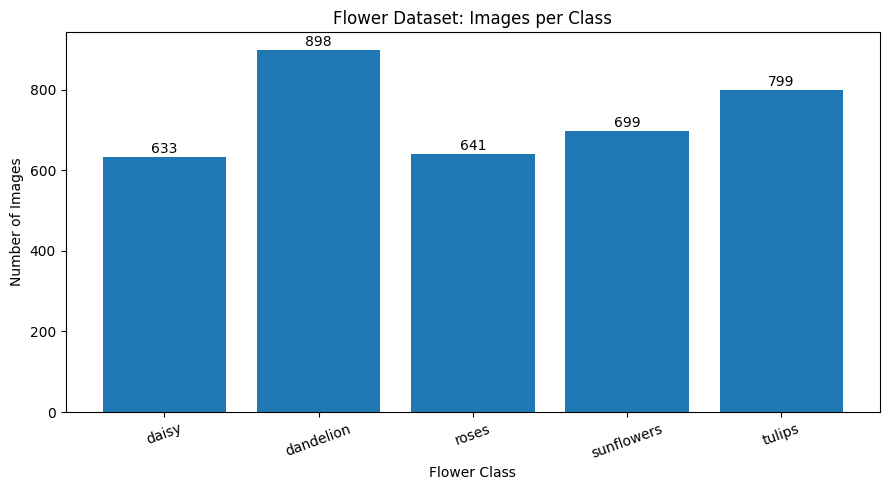

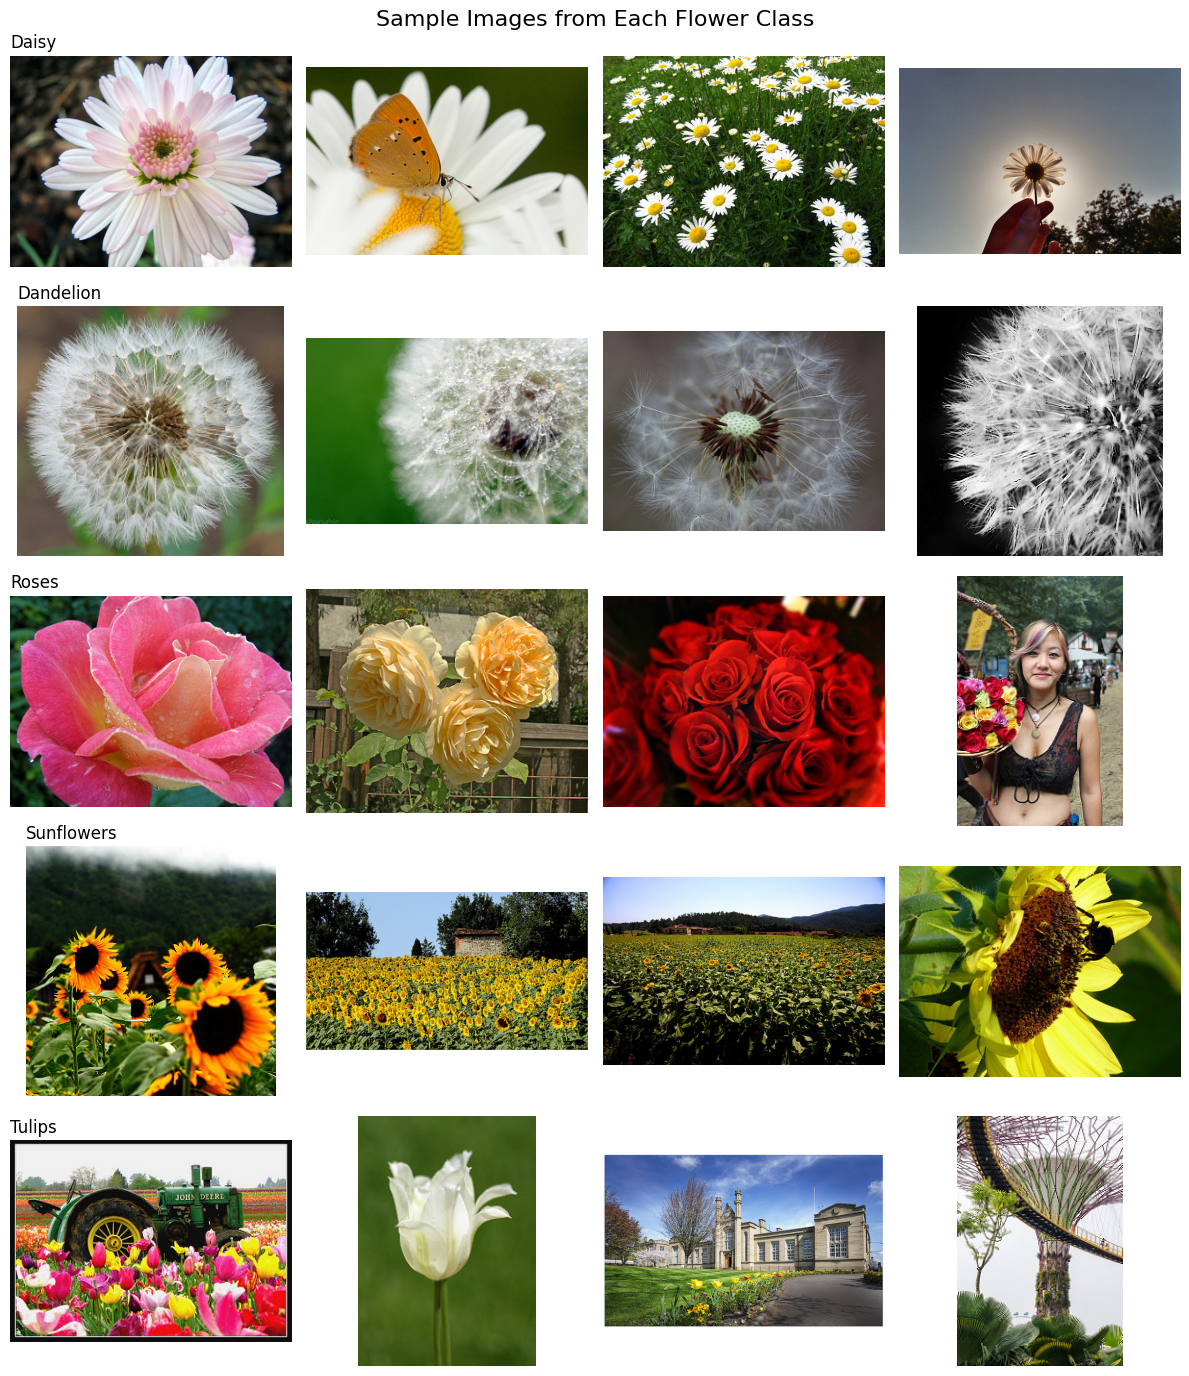

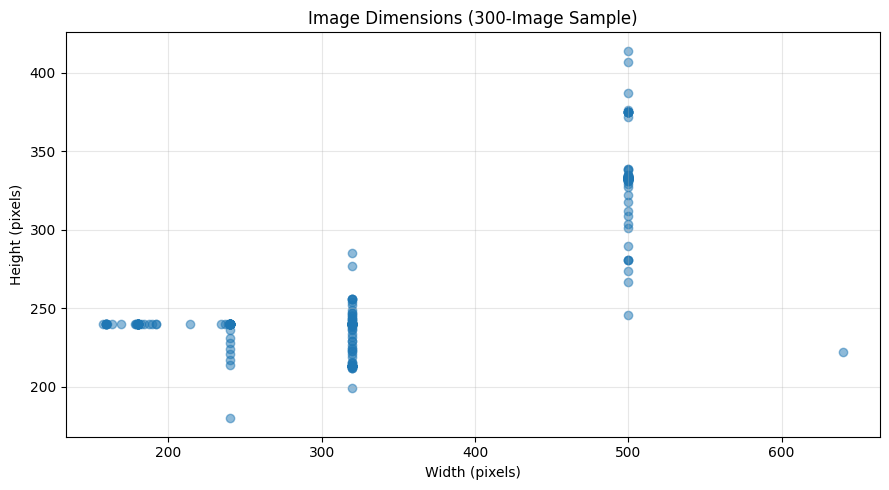

EDA visualizations saved to: /content/drive/MyDrive/ML_Assignment/FlowerVision/results


In [ ]:
import matplotlib.pyplot as plt
import random
from PIL import Image
from pathlib import Path
import numpy as np

random.seed(42)
np.random.seed(42)

# --------------------------------------------------
# 1. CLASS DISTRIBUTION
# --------------------------------------------------
plt.figure(figsize=(9, 5))

classes = list(class_counts.keys())
counts = list(class_counts.values())

bars = plt.bar(classes, counts)

plt.title("Flower Dataset: Images per Class")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 10,
        str(count),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "class_distribution.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 2. SAMPLE IMAGE GALLERY
# --------------------------------------------------
fig, axes = plt.subplots(5, 4, figsize=(12, 14))

for row, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(EXTRACT_DIR, class_name)

    image_files = [
        f for f in os.listdir(class_dir)
        if Path(f).suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_images = random.sample(image_files, 4)

    for col, filename in enumerate(selected_images):
        image_path = os.path.join(class_dir, filename)

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(class_name.capitalize(), loc="left")

fig.suptitle("Sample Images from Each Flower Class", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "sample_image_gallery.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 3. IMAGE DIMENSIONS DISTRIBUTION
# Sample 300 images to avoid unnecessary Drive reads
# --------------------------------------------------
all_image_paths = []

for class_name in CLASS_NAMES:
    class_dir = os.path.join(EXTRACT_DIR, class_name)

    for filename in os.listdir(class_dir):
        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
            all_image_paths.append(os.path.join(class_dir, filename))

sample_paths = random.sample(all_image_paths, min(300, len(all_image_paths)))

widths = []
heights = []

for image_path in sample_paths:
    with Image.open(image_path) as img:
        widths.append(img.width)
        heights.append(img.height)

plt.figure(figsize=(9, 5))

plt.scatter(widths, heights, alpha=0.5)

plt.title("Image Dimensions (300-Image Sample)")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "image_dimensions.png"),
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("EDA visualizations saved to:", RESULTS_DIR)

## EDA Findings and Interpretation

The exploratory analysis revealed several characteristics of the flower dataset.

**Class distribution:** The dataset is imbalanced across the five flower categories. Dandelions have the highest number of images, while Daisies have the lowest. This imbalance will be considered when evaluating the model, particularly when examining per-class performance rather than relying solely on accuracy.

**Visual diversity:** The sample gallery shows considerable variation in image composition. Flowers appear in close-up photographs, gardens, fields, and other environments. Differences in lighting, backgrounds, orientation, and the amount of space occupied by the flower introduce visual complexity that the model must learn to handle.

**Image dimensions:** The sampled images have varying widths and heights. A consistent input size is therefore required for model training. Images will be resized during preprocessing, while pixel values will be normalized to support stable learning.

Overall, the dataset provides realistic visual variation, but the differences in composition and class distribution may present challenges during training and evaluation.

## Dataset Splitting

The dataset is divided into training, validation, and testing subsets using stratified sampling. Stratification ensures that the proportions of the five flower categories remain approximately consistent across the subsets.

The training subset is used to fit the model, the validation subset is used to monitor training performance and guide model adjustments, and the test subset is reserved for final evaluation.

A fixed random seed is used to make the partitioning reproducible. The image files remain in their original directories; only their paths and labels are assigned to the respective subsets.

In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from collections import Counter

SEED = 42

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
CLASS_TO_INDEX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# Collect image paths and labels
image_paths = []
image_labels = []

for class_name in CLASS_NAMES:
    class_dir = os.path.join(EXTRACT_DIR, class_name)

    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            image_paths.append(os.path.join(class_dir, filename))
            image_labels.append(CLASS_TO_INDEX[class_name])

image_paths = np.array(image_paths)
image_labels = np.array(image_labels, dtype=np.int32)

# First split: 70% train, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

# Second split: divide temporary set equally into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Create a record of the split
split_df = pd.DataFrame({
    "filepath": np.concatenate([train_paths, val_paths, test_paths]),
    "label": np.concatenate([train_labels, val_labels, test_labels]),
    "split": (
        ["train"] * len(train_paths)
        + ["validation"] * len(val_paths)
        + ["test"] * len(test_paths)
    )
})

split_df["class_name"] = split_df["label"].map(
    dict(enumerate(CLASS_NAMES))
)

# Save the split for reproducibility
split_csv_path = os.path.join(SPLIT_DATA_DIR, "dataset_split.csv")
split_df.to_csv(split_csv_path, index=False)

# Display split sizes and class distribution
for split_name, labels in [
    ("Train", train_labels),
    ("Validation", val_labels),
    ("Test", test_labels)
]:
    distribution = Counter(CLASS_NAMES[label] for label in labels)
    print(f"\n{split_name}: {len(labels)} images")
    for class_name in CLASS_NAMES:
        print(f"  {class_name:12}: {distribution[class_name]}")

print("\nTotal images:", len(image_paths))
print("Split file saved:", split_csv_path)


Train: 2569 images
  daisy       : 443
  dandelion   : 629
  roses       : 449
  sunflowers  : 489
  tulips      : 559

Validation: 550 images
  daisy       : 95
  dandelion   : 134
  roses       : 96
  sunflowers  : 105
  tulips      : 120

Test: 551 images
  daisy       : 95
  dandelion   : 135
  roses       : 96
  sunflowers  : 105
  tulips      : 120

Total images: 3670
Split file saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/splits/dataset_split.csv


The dataset is divided into three subsets for model development and evaluation:

- **Training set (70%):** Used to train the model.
- **Validation set (15%):** Used to monitor model performance during training and support model optimization.
- **Test set (15%):** Used to evaluate the final model on previously unseen images.

A stratified split is used to maintain the proportion of each flower category across all three subsets. A random seed of 42 ensures reproducibility.

The resulting split information is also saved as a CSV file for future reference.


## Image Preprocessing and Input Pipeline

The images have varying dimensions and must be converted into a consistent format before being processed by the neural network.

TensorFlow's data pipeline is used to load and preprocess the images efficiently. Each image is decoded as RGB, resized to 180 × 180 pixels, and normalized to the range [0, 1]. The datasets are batched and prefetched to improve training efficiency.

Training data is shuffled to reduce the effect of sample ordering. Validation and test datasets are not shuffled, ensuring consistent evaluation and prediction ordering.

Before images are passed to the model, they undergo preprocessing to ensure consistent input formatting.

The preprocessing pipeline performs the following operations:

1. Reads image files from their respective file paths.
2. Decodes images into three colour channels (RGB).
3. Resizes images to 180 × 180 pixels.
4. Converts pixel values to floating-point numbers and normalizes them to the range [0, 1].
5. Converts class labels into one-hot encoded vectors.

The processed images are grouped into batches of 32. The training dataset is shuffled, and prefetching is used to improve data-loading efficiency.

Separate TensorFlow datasets are created for training, validation, and testing.


In [6]:
import tensorflow as tf

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.one_hot(label, depth=len(CLASS_NAMES))

    return image, label

def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_dataset = create_dataset(train_paths, train_labels, training=True)
val_dataset = create_dataset(val_paths, val_labels, training=False)
test_dataset = create_dataset(test_paths, test_labels, training=False)

print("TensorFlow input pipeline created successfully.")
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

TensorFlow input pipeline created successfully.
Training batches: 81
Validation batches: 18
Test batches: 18


The preprocessing pipeline is tested to confirm that images and labels have the expected shapes and data types.

The checks include:

- Image batch dimensions.
- One-hot encoded label dimensions.
- Image data type.
- Normalized pixel value range.
- Correct decoding of a sample label into its corresponding flower category.

This verification helps identify preprocessing issues before model evaluation.


In [7]:
images, labels = next(iter(train_dataset))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("Label example:", labels[0].numpy())
print("Decoded class:", CLASS_NAMES[tf.argmax(labels[0]).numpy()])

Image batch shape: (32, 180, 180, 3)
Label batch shape: (32, 5)
Image dtype: <dtype: 'float32'>
Pixel range: 0.0 to 1.0
Label example: [0. 1. 0. 0. 0.]
Decoded class: dandelion


## Model Architecture: Transfer Learning with MobileNetV2

FlowerVision uses MobileNetV2, a convolutional neural network pretrained on ImageNet, as its feature extractor. Transfer learning allows the project to benefit from previously learned visual representations rather than learning all features from a relatively small dataset from scratch.

The pretrained base is initially frozen to preserve its learned features. A new classification head is added to predict the five flower categories. Data augmentation is applied during training to improve generalization across variations in orientation and image appearance.

The model outputs a probability distribution over the five flower classes using the softmax activation function. The class with the highest predicted probability is selected as the predicted category.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(SEED)

# Data augmentation (applied only during training)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="data_augmentation")

# Pretrained convolutional base
base_model = keras.applications.MobileNetV2(
    input_shape=(180, 180, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers for initial training
base_model.trainable = False

# Build complete model
inputs = keras.Input(shape=(180, 180, 3), name="input_image")

x = data_augmentation(inputs)

# Our pipeline normalizes pixels to [0, 1].
# MobileNetV2 expects pixels scaled to [-1, 1].
x = layers.Rescaling(scale=2.0, offset=-1.0, name="mobilenet_scaling")(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="dropout")(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax",
    name="flower_predictions"
)(x)

model = keras.Model(inputs, outputs, name="FlowerVision")

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("FlowerVision model created successfully.")
print("Model parameters:", f"{model.count_params():,}")
print("Class order:", CLASS_NAMES)

/tmp/ipykernel_370/4136979402.py:15: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
FlowerVision model created successfully.
Model parameters: 2,264,389
Class order: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
model.summary()

Model: "FlowerVision"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_scaling (Rescaling)   │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower_predictions (Dense)      │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Initial Model Training

The initial training phase uses transfer learning. MobileNetV2's pretrained feature extraction layers are frozen, and only the newly added classification head is trained on the flower dataset.

Early stopping monitors validation loss and restores the weights from the best epoch. A learning-rate reduction callback lowers the learning rate when validation performance plateaus. Model checkpoints ensure that the best-performing model is saved to Google Drive throughout training.

Training and validation metrics are recorded for subsequent analysis.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

BEST_MODEL_PATH = os.path.join(MODELS_DIR, "flower_vision_best.keras")

callbacks = [
    ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

EPOCHS = 12

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining complete.")
print("Best model saved at:", BEST_MODEL_PATH)

Epoch 1/12
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.4245 - loss: 1.4794
Epoch 1: val_loss improved from None to 0.56979, saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_best.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 161ms/step - accuracy: 0.5839 - loss: 1.0747 - val_accuracy: 0.8000 - val_loss: 0.5698 - learning_rate: 0.0010
Epoch 2/12
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.7746 - loss: 0.6023
Epoch 2: val_loss improved from 0.56979 to 0.46380, saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_best.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 109ms/step - accuracy: 0.7890 - loss: 0.5676 - val_accuracy: 0.8400 - val_loss: 0.4638 - learning_rate: 0.0010
Epoch 3/12
80/81

## Training Performance Analysis

The training history is visualized using accuracy and loss curves for both the training and validation datasets.

Accuracy shows how frequently the model correctly classifies images, while loss measures the error associated with its predictions. Comparing training and validation curves helps assess learning progress, convergence, and potential overfitting.

The plots are saved as project artifacts for documentation and further analysis.

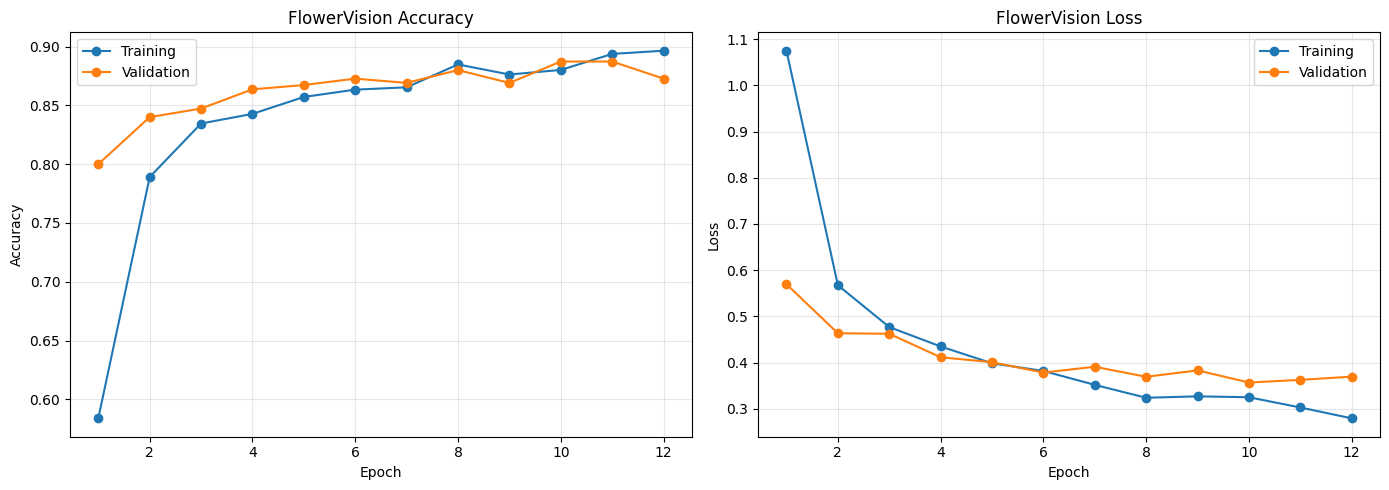

Training history saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/training_history.csv
Training curves saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/training_curves.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_csv_path = os.path.join(RESULTS_DIR, "training_history.csv")
history_df.to_csv(history_csv_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history_df.index, history_df["accuracy"], marker="o", label="Training")
axes[0].plot(history_df.index, history_df["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("FlowerVision Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history_df.index, history_df["loss"], marker="o", label="Training")
axes[1].plot(history_df.index, history_df["val_loss"], marker="o", label="Validation")
axes[1].set_title("FlowerVision Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

curve_path = os.path.join(RESULTS_DIR, "training_curves.png")
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()

print("Training history saved:", history_csv_path)
print("Training curves saved:", curve_path)

### Training Performance Analysis

The training and validation accuracy increased consistently throughout training, indicating that the model was learning useful features for flower classification. Training accuracy increased from approximately 58% to 89.7%, while validation accuracy reached a peak of 88.7%.

Training and validation loss decreased substantially during the initial epochs, showing that the model progressively improved its predictions. Although training loss continued to decrease, validation loss fluctuated slightly during the later epochs, suggesting that the model was approaching convergence with minor signs of overfitting.

The relatively small gap between training and validation accuracy suggests that the model generalizes reasonably well to unseen validation data. The best model was retained using checkpointing based on validation loss, ensuring that the best-performing version was saved rather than simply using the final epoch.

In [ ]:
from tensorflow import keras

# Load the best saved model
best_model = keras.models.load_model(
    os.path.join(MODELS_DIR, "flower_vision_best.keras")
)

# Evaluate on the untouched test dataset
test_loss, test_accuracy = best_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 138ms/step - accuracy: 0.8838 - loss: 0.3502

Test Loss: 0.3502
Test Accuracy: 0.8838 (88.38%)


### Detailed Model Evaluation

Accuracy provides an overall measure of the model's performance, but it does not show how well individual flower categories are classified. Precision, recall, and F1-score provide a more detailed evaluation, particularly because the dataset contains an unequal number of images per class.

A confusion matrix will also be used to identify which flower categories the model confuses most frequently. This helps determine where the model performs well and where further improvements may be needed.

FINAL TEST METRICS
----------------------------------------
Accuracy:  0.8838
Precision: 0.8821
Recall:    0.8838
F1-score:  0.8812

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       daisy     0.8333    0.8947    0.8629        95
   dandelion     0.9338    0.9407    0.9373       135
       roses     0.7982    0.9062    0.8488        96
  sunflowers     0.9490    0.8857    0.9163       105
      tulips     0.8962    0.7917    0.8407       120

    accuracy                         0.8838       551
   macro avg     0.8821    0.8838    0.8812       551
weighted avg     0.8876    0.8838    0.8840       551



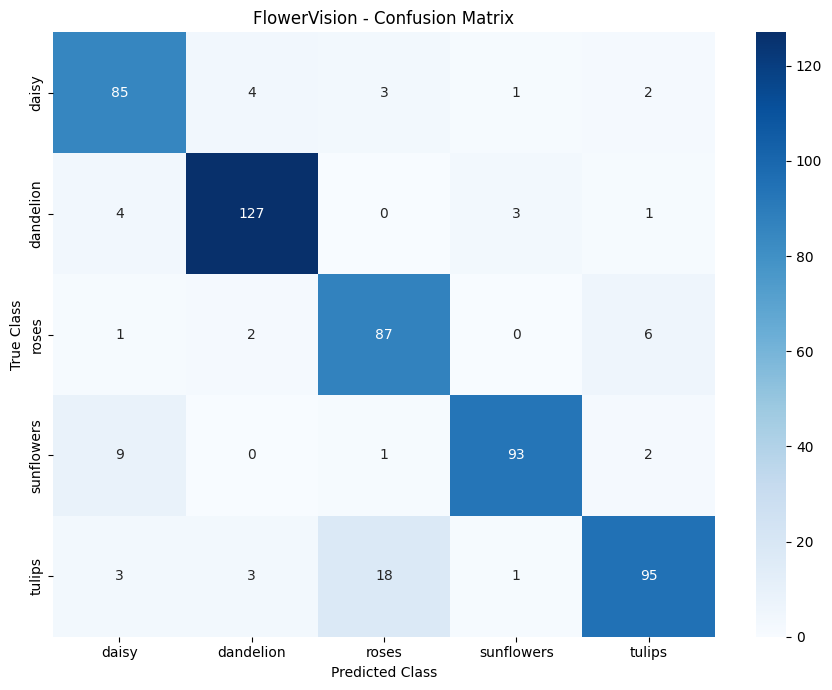


Saved confusion matrix: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/confusion_matrix.png
Saved classification report: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/classification_report.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Generate predictions for the test dataset
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, average="macro")
test_recall = recall_score(y_true, y_pred, average="macro")
test_f1 = f1_score(y_true, y_pred, average="macro")

print("FINAL TEST METRICS")
print("-" * 40)
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-score:  {test_f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("FlowerVision - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

# Save the confusion matrix
cm_path = os.path.join(RESULTS_DIR, "confusion_matrix.png")
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
report_path = os.path.join(RESULTS_DIR, "classification_report.csv")
report_df.to_csv(report_path)

print("\nSaved confusion matrix:", cm_path)
print("Saved classification report:", report_path)

### Test Results and Discussion

FlowerVision achieved an overall test accuracy of 88.38%, with a macro F1-score of 88.12%, demonstrating that the model can classify flower images with relatively high accuracy across the five categories.

Dandelions were classified most effectively, achieving an F1-score of 93.73%, while sunflowers achieved the highest precision at 94.90%. Tulips had the lowest recall of 79.17%, indicating that the model struggled to correctly identify some tulip images. The confusion matrix revealed that 18 tulip images were incorrectly classified as roses, making this the most frequent misclassification between two classes. Sunflowers were also occasionally misclassified as daisies.

These results suggest that the model has learned useful visual features for flower recognition but still struggles with visually similar categories. Further improvements could include fine-tuning the pretrained model, increasing training data diversity, and applying additional data augmentation.

### Visual Prediction Examples

To further evaluate the model, sample images from the unseen test dataset were used to visualize FlowerVision's predictions. Each image is displayed alongside its actual class, predicted class, and prediction confidence.

Correct predictions and misclassifications are distinguished visually. This provides a more intuitive understanding of the model's performance and helps identify examples where the model struggles to distinguish between flower categories.

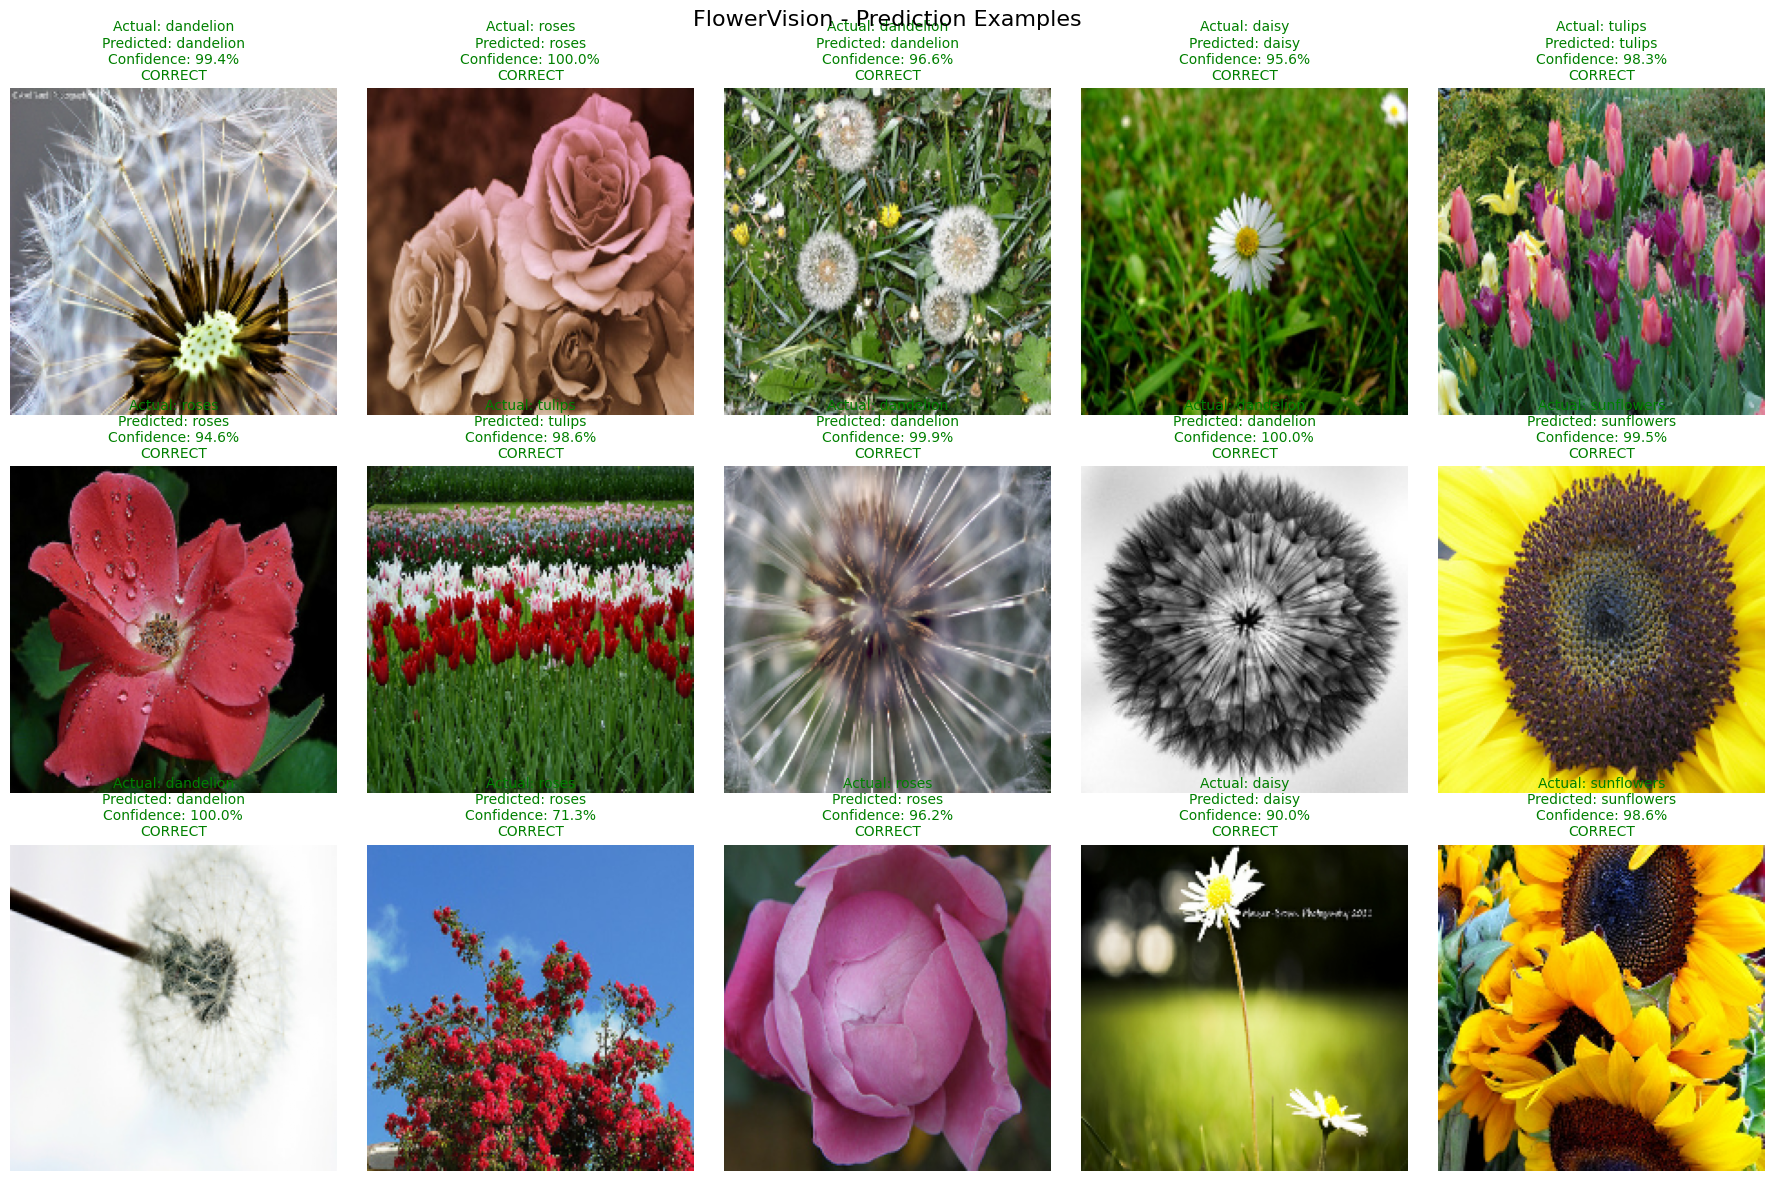

Prediction examples saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/prediction_examples.png


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Collect test images and prediction probabilities
all_test_images = []
all_test_labels = []
all_test_probabilities = []

for images, labels in test_dataset:
    probabilities = best_model.predict(images, verbose=0)

    all_test_images.extend(images.numpy())
    all_test_labels.extend(np.argmax(labels.numpy(), axis=1))
    all_test_probabilities.extend(probabilities)

all_test_images = np.array(all_test_images)
all_test_labels = np.array(all_test_labels)
all_test_probabilities = np.array(all_test_probabilities)

# Get predicted classes and confidence scores
all_predictions = np.argmax(all_test_probabilities, axis=1)
all_confidences = np.max(all_test_probabilities, axis=1) * 100

# Select 15 random test images reproducibly
random.seed(42)
sample_indices = random.sample(range(len(all_test_images)), 15)

# Visualize predictions
fig, axes = plt.subplots(3, 5, figsize=(18, 12))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    actual = CLASS_NAMES[all_test_labels[idx]]
    predicted = CLASS_NAMES[all_predictions[idx]]
    confidence = all_confidences[idx]
    correct = actual == predicted

    ax.imshow(all_test_images[idx])
    ax.axis("off")

    status = "CORRECT" if correct else "INCORRECT"
    color = "green" if correct else "red"

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%\n"
        f"{status}",
        color=color,
        fontsize=10
    )

plt.suptitle("FlowerVision - Prediction Examples", fontsize=16)
plt.tight_layout()

# Save visualization
prediction_examples_path = os.path.join(
    RESULTS_DIR, "prediction_examples.png"
)

plt.savefig(prediction_examples_path, dpi=150, bbox_inches="tight")
plt.show()

print("Prediction examples saved:", prediction_examples_path)

### Model Optimization: Fine-Tuning

Transfer learning was used in the initial model by freezing the pretrained MobileNetV2 feature extractor and training only the classification head. Fine-tuning is the next optimization step, where selected pretrained layers are unfrozen and trained using a lower learning rate.

This allows the model to adapt its learned image features to the flower dataset while reducing the risk of destroying useful pretrained knowledge. The fine-tuned model will be evaluated against the original model to determine whether this optimization improves performance.

In [ ]:
from tensorflow import keras

# Start from the original best model — don't modify our baseline
fine_tuned_model = keras.models.load_model(
    os.path.join(MODELS_DIR, "flower_vision_best.keras")
)

# Locate MobileNetV2 inside the model
base_model = next(
    layer for layer in fine_tuned_model.layers
    if isinstance(layer, keras.Model) and "mobilenet" in layer.name.lower()
)

# Unfreeze the backbone, but keep most layers frozen
base_model.trainable = True

# Fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very low learning rate
fine_tuned_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Base model:", base_model.name)
print("Trainable parameters:",
      sum(tf.size(w).numpy() for w in fine_tuned_model.trainable_weights))
print("Fine-tuning configuration ready.")

Base model: mobilenetv2_1.00_224
Trainable parameters: 1517125
Fine-tuning configuration ready.


## Model Fine-Tuning

Fine-tuning was performed to improve the model's ability to recognize flower-specific visual features. Instead of training the entire pretrained MobileNetV2 network from scratch, the process started with the weights from the original transfer learning model.

The last 30 layers of the MobileNetV2 feature extractor were unfrozen, while earlier layers and Batch Normalization layers remained frozen. This allowed selected pretrained features to adapt to the flower dataset while preserving previously learned representations.

A low learning rate of 0.00001 was used to make gradual adjustments to the pretrained weights. Early stopping was applied to prevent unnecessary training, while learning rate reduction helped the model adjust when validation loss stopped improving. The best model checkpoint was saved based on validation loss and restored after training.

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

fine_tune_checkpoint = os.path.join(
    MODELS_DIR, "flower_vision_finetuned_best.keras"
)

fine_tune_callbacks = [
    ModelCheckpoint(
        fine_tune_checkpoint,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

fine_tune_history = fine_tuned_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=8,
    callbacks=fine_tune_callbacks
)

Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.9010 - loss: 0.2771
Epoch 1: val_loss improved from None to 0.35599, saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_finetuned_best.keras
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 138ms/step - accuracy: 0.8984 - loss: 0.2807 - val_accuracy: 0.8855 - val_loss: 0.3560 - learning_rate: 1.0000e-05
Epoch 2/8
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.8978 - loss: 0.2635
Epoch 2: val_loss did not improve from 0.35599
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.9000 - loss: 0.2684 - val_accuracy: 0.8818 - val_loss: 0.3564 - learning_rate: 1.0000e-05
Epoch 3/8
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9106 - loss: 0.2414
Epoch 3: val_loss improved from 0.35599 to 0.31857, saving model to /content/drive/MyDrive/ML_Assignment/FlowerVision/models

## Model Optimization and Comparison

After evaluating the original transfer learning model, fine-tuning was performed to improve its ability to recognize flower-specific features. The last 30 layers of MobileNetV2 were unfrozen, while earlier layers and Batch Normalization layers remained frozen. A smaller learning rate of 0.00001 was used to prevent large changes to the pretrained weights.

The fine-tuned model was trained for up to eight epochs using early stopping and learning rate reduction callbacks. The best checkpoint was selected based on validation loss.

Both the original model and fine-tuned model were evaluated using the same test dataset. Accuracy, precision, recall, F1-score, and loss were compared to determine whether fine-tuning improved classification performance and generalization to unseen images.

In [ ]:
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Load the best fine-tuned checkpoint
fine_tuned_best = keras.models.load_model(fine_tune_checkpoint)

# Evaluate both models on the same test set
original_loss, original_accuracy = best_model.evaluate(
    test_dataset, verbose=0
)

fine_loss, fine_accuracy = fine_tuned_best.evaluate(
    test_dataset, verbose=0
)

# Generate predictions for macro metrics
def get_predictions(model, dataset):
    true_labels = []
    predicted_labels = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        true_labels.extend(np.argmax(labels.numpy(), axis=1))
        predicted_labels.extend(np.argmax(probabilities, axis=1))

    return np.array(true_labels), np.array(predicted_labels)

y_true, original_predictions = get_predictions(best_model, test_dataset)
_, fine_predictions = get_predictions(fine_tuned_best, test_dataset)

# Create comparison table
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 (Macro)", "Loss"],
    "Original Model": [
        accuracy_score(y_true, original_predictions),
        precision_score(y_true, original_predictions, average="macro"),
        recall_score(y_true, original_predictions, average="macro"),
        f1_score(y_true, original_predictions, average="macro"),
        original_loss
    ],
    "Fine-Tuned Model": [
        accuracy_score(y_true, fine_predictions),
        precision_score(y_true, fine_predictions, average="macro"),
        recall_score(y_true, fine_predictions, average="macro"),
        f1_score(y_true, fine_predictions, average="macro"),
        fine_loss
    ]
})

comparison["Original Model"] = comparison["Original Model"].astype(float)
comparison["Fine-Tuned Model"] = comparison["Fine-Tuned Model"].astype(float)

display(comparison.round(4))

# Save comparison results
comparison_path = os.path.join(RESULTS_DIR, "model_comparison.csv")
comparison.to_csv(comparison_path, index=False)

print("\nComparison saved:", comparison_path)

,Metric,Original Model,Fine-Tuned Model
0,Accuracy,0.8838,0.8893
1,Precision (Macro),0.8821,0.8869
2,Recall (Macro),0.8838,0.8878
3,F1 (Macro),0.8812,0.8871
4,Loss,0.3502,0.3040



Comparison saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/model_comparison.csv


## Model Comparison Results and Selection

The fine-tuned model outperformed the original transfer learning model across all evaluated metrics. Test accuracy increased from 88.38% to 88.93%, while macro precision, recall, and F1-score also improved slightly.

Test loss decreased from 0.3502 to 0.3040, indicating improved performance on the test dataset. Although the improvements were relatively small, the consistent increase across the evaluation metrics suggests that fine-tuning the last 30 layers of MobileNetV2 helped the model adapt to the flower classification task.

Based on these results, the fine-tuned model was selected as the final FlowerVision model for subsequent deployment and application development.

## Final Model Preparation

Following the evaluation and comparison of the original and fine-tuned models, the fine-tuned MobileNetV2 model was selected as the final FlowerVision model. It achieved better performance across the evaluated metrics, including accuracy, precision, recall, F1-score, and test loss.

The selected model is saved separately from experimental checkpoints to establish a clear production version. The class labels are also saved to ensure that model predictions are mapped to the correct flower categories during inference.

This preparation allows the trained model to be reused by external applications, including the FlowerVision prediction API, without retraining.

In [ ]:
import json
import os

# Production model directory
FINAL_MODEL_DIR = os.path.join(MODELS_DIR, "production")
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

# Save the selected model
FINAL_MODEL_PATH = os.path.join(
    FINAL_MODEL_DIR, "flower_vision_final.keras"
)

fine_tuned_best.save(FINAL_MODEL_PATH)

# Save class labels in prediction order
CLASS_NAMES_PATH = os.path.join(
    FINAL_MODEL_DIR, "class_names.json"
)

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(CLASS_NAMES, f, indent=4)

print("Final model saved:", FINAL_MODEL_PATH)
print("Class names saved:", CLASS_NAMES_PATH)
print("\nClass order:")
for index, name in enumerate(CLASS_NAMES):
    print(f"{index}: {name}")

Final model saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/production/flower_vision_final.keras
Class names saved: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/production/class_names.json

Class order:
0: daisy
1: dandelion
2: roses
3: sunflowers
4: tulips


### Production Model Verification

Before integrating the model into the prediction API, the saved production model is reloaded from its file path. This verifies that the model has been saved correctly and can be loaded independently of the training process.

A sample image from the test dataset is then passed through the reloaded model to confirm that it produces a valid prediction with a probability distribution across the five flower classes. This verifies the model's basic inference functionality before API development.

In [ ]:
import json
import numpy as np
from tensorflow import keras

# Reload model from production directory
production_model = keras.models.load_model(FINAL_MODEL_PATH)

# Reload class labels
with open(CLASS_NAMES_PATH, "r") as f:
    production_class_names = json.load(f)

# Use one image from the test set
sample_index = 0
sample_image = all_test_images[sample_index]

# Predict using the reloaded production model
prediction = production_model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

predicted_index = np.argmax(prediction)
predicted_flower = production_class_names[predicted_index]
confidence = float(prediction[predicted_index]) * 100

# Display verification results
print("PRODUCTION MODEL VERIFICATION")
print("-" * 35)
print("Model loaded successfully:", production_model.name)
print("Input shape:", sample_image.shape)
print("Number of classes:", len(production_class_names))
print("Predicted flower:", predicted_flower)
print(f"Confidence: {confidence:.2f}%")
print("Probability output shape:", prediction.shape)
print("Probabilities sum to 1:", np.isclose(prediction.sum(), 1.0))

PRODUCTION MODEL VERIFICATION
-----------------------------------
Model loaded successfully: FlowerVision
Input shape: (180, 180, 3)
Number of classes: 5
Predicted flower: roses
Confidence: 93.26%
Probability output shape: (5,)
Probabilities sum to 1: True



## Loading the Saved Fine-Tuned Model

The previously trained and fine-tuned FlowerVision model is stored in Google Drive.

Before proceeding with final model evaluation, the saved model file is checked to confirm that it exists and is accessible.

This allows the evaluation process to continue using the existing trained model without repeating the training process.


In [8]:
import os

FINAL_MODEL_PATH = os.path.join(
    MODELS_DIR,
    "production",
    "flower_vision_final.keras"
)

print("Final model exists:", os.path.exists(FINAL_MODEL_PATH))
print("Model path:", FINAL_MODEL_PATH)

if os.path.exists(FINAL_MODEL_PATH):
    print("Model size (MB):", round(
        os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024), 2
    ))

Final model exists: True
Model path: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/production/flower_vision_final.keras
Model size (MB): 20.79



### Loading the Fine-Tuned Model

The saved fine-tuned model is loaded from Google Drive for final evaluation.

Loading the existing model allows us to assess its performance on the test dataset without repeating the training process.


In [9]:

import tensorflow as tf

final_model = tf.keras.models.load_model(FINAL_MODEL_PATH)

print("Fine-tuned model loaded successfully!")
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)


Fine-tuned model loaded successfully!
Input shape: (None, 180, 180, 3)
Output shape: (None, 5)



###  Generating Predictions on the Test Dataset

The fine-tuned model is evaluated using the reserved test dataset, which contains images that were not used during training or validation.

The model generates a probability distribution across the five flower categories for each test image. The category with the highest predicted probability is selected as the predicted class.

These predictions are then compared with the true labels to measure the model's classification performance.


In [10]:

import numpy as np

# Generate predictions using the fine-tuned model
y_prob = final_model.predict(test_dataset)

# Convert predicted probabilities into class indices
y_pred = np.argmax(y_prob, axis=1)

# Extract true class indices from the test dataset
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for _, labels in test_dataset
])

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))
print("Number of true labels:", len(y_true))
print("Predicted classes:", y_pred.shape)
print("True classes:", y_true.shape)


18/18 ━━━━━━━━━━━━━━━━━━━━ 14s 487ms/step
Predictions generated successfully!
Number of predictions: 551
Number of true labels: 551
Predicted classes: (551,)
True classes: (551,)


###  Evaluating the Fine-Tuned Model

The model's predictions are evaluated against the true labels from the test dataset.

Four classification metrics are calculated: accuracy, precision, recall, and F1-score. Macro averaging is used for precision, recall, and F1-score to give equal importance to each flower category.

These metrics provide a broader understanding of the model's performance across all five classes.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_true, y_pred)

test_precision = precision_score(
    y_true, y_pred, average="macro"
)

test_recall = recall_score(
    y_true, y_pred, average="macro"
)

test_f1 = f1_score(
    y_true, y_pred, average="macro"
)

# Display results
print("FINE-TUNED MODEL EVALUATION")
print("-" * 40)
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")

FINE-TUNED MODEL EVALUATION
----------------------------------------
Accuracy:  0.8893
Precision: 0.8869
Recall:    0.8878
F1-Score:  0.8871


###  Detailed Classification Report

A classification report is generated to examine the fine-tuned model's performance on each flower category individually.

The report includes precision, recall, F1-score, and support for each class. This helps identify categories the model classifies well and categories where further improvement may be needed.

In [12]:
from sklearn.metrics import classification_report

print("FINE-TUNED MODEL CLASSIFICATION REPORT")
print("-" * 55)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

FINE-TUNED MODEL CLASSIFICATION REPORT
-------------------------------------------------------
              precision    recall  f1-score   support

       daisy     0.8400    0.8842    0.8615        95
   dandelion     0.9270    0.9407    0.9338       135
       roses     0.8673    0.8854    0.8763        96
  sunflowers     0.9307    0.8952    0.9126       105
      tulips     0.8696    0.8333    0.8511       120

    accuracy                         0.8893       551
   macro avg     0.8869    0.8878    0.8871       551
weighted avg     0.8898    0.8893    0.8893       551



In [15]:
import pandas as pd

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1
    ]
})

METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "fine_tuned_evaluation_metrics.csv"
)

metrics_df.to_csv(METRICS_PATH, index=False)

print("Evaluation metrics saved to:", METRICS_PATH)

Evaluation metrics saved to: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/fine_tuned_evaluation_metrics.csv


###  Confusion Matrix

A confusion matrix is generated to compare the actual flower categories with the categories predicted by the fine-tuned model.

It shows the number of correctly classified images and the number of images incorrectly assigned to other categories. This helps identify patterns in the model's classification errors.

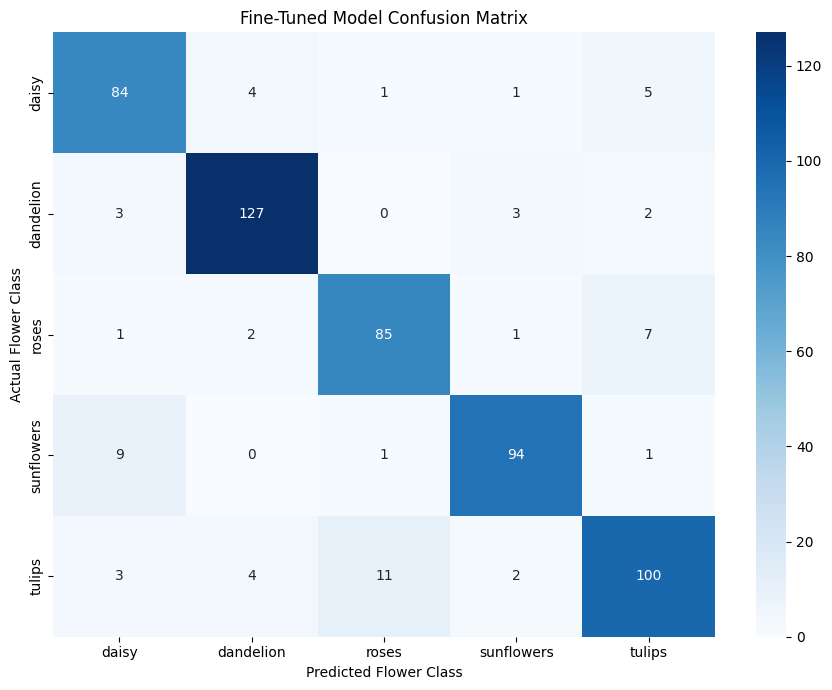

Confusion matrix saved to: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/fine_tuned_confusion_matrix.png


In [14]:
# Save the confusion matrix to Google Drive
CONFUSION_MATRIX_PATH = os.path.join(
    RESULTS_DIR,
    "fine_tuned_confusion_matrix.png"
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Fine-Tuned Model Confusion Matrix")
plt.xlabel("Predicted Flower Class")
plt.ylabel("Actual Flower Class")
plt.tight_layout()

plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Confusion matrix saved to:", CONFUSION_MATRIX_PATH)

#### Confusion Matrix Analysis

The confusion matrix shows that the fine-tuned model correctly classified 490 out of 551 test images.

Dandelions achieved the strongest classification performance, with 127 out of 135 images correctly identified. Sunflowers also performed well, with 94 out of 105 images correctly classified.

The most noticeable classification errors involved tulips and roses. Eleven actual tulip images were incorrectly predicted as roses, while seven actual rose images were predicted as tulips. Additionally, nine sunflower images were classified as daisies.

These results suggest that the model performs well overall but still struggles to distinguish certain flower categories. Further improvements could focus on these commonly confused classes.

###  Saving the Classification Report

The detailed classification report is exported as a CSV file and stored in the project's results directory in Google Drive. This preserves the individual precision, recall, F1-score, and support values for each flower category for future analysis and reporting.

In [16]:
from sklearn.metrics import classification_report
import pandas as pd
import os

# Generate detailed classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)

# Convert report into a DataFrame
report_df = pd.DataFrame(report).transpose()

# Save report to Google Drive
REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "fine_tuned_classification_report.csv"
)

report_df.to_csv(REPORT_PATH)

print("Classification report saved successfully!")
print("Saved to:", REPORT_PATH)

display(report_df)

Classification report saved successfully!
Saved to: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/fine_tuned_classification_report.csv


,precision,recall,f1-score,support
daisy,0.840000,0.884211,0.861538,95.000000
dandelion,0.927007,0.940741,0.933824,135.000000
roses,0.867347,0.885417,0.876289,96.000000
sunflowers,0.930693,0.895238,0.912621,105.000000
tulips,0.869565,0.833333,0.851064,120.000000
accuracy,0.889292,0.889292,0.889292,0.889292
macro avg,0.886923,0.887788,0.887067,551.000000
weighted avg,0.889804,0.889292,0.889272,551.000000


###  Checking for the Original Model

Before comparing the original and fine-tuned models, the project directory is checked for a separately saved original model checkpoint.

This helps establish whether both model versions are available for a fair comparison without repeating the training process.

In [18]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ML_Assignment/FlowerVision"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

print("Project directory:", PROJECT_DIR)
print("Models directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)

print("Models directory exists:", os.path.exists(MODEL_DIR))

Project directory: /content/drive/MyDrive/ML_Assignment/FlowerVision
Models directory: /content/drive/MyDrive/ML_Assignment/FlowerVision/models
Results directory: /content/drive/MyDrive/ML_Assignment/FlowerVision/results
Models directory exists: True


In [19]:
import os

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

print("MODEL FILES")
print("-" * 45)

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        if file.endswith((".keras", ".h5")):
            full_path = os.path.join(root, file)
            size_mb = os.path.getsize(full_path) / (1024 * 1024)

            print(f"File: {file}")
            print(f"Path: {full_path}")
            print(f"Size: {size_mb:.2f} MB")
            print("-" * 45)

MODEL FILES
---------------------------------------------
File: flower_vision_best.keras
Path: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_best.keras
Size: 9.26 MB
---------------------------------------------
File: flower_vision_finetuned_best.keras
Path: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/flower_vision_finetuned_best.keras
Size: 20.79 MB
---------------------------------------------
File: flower_vision_final.keras
Path: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/production/flower_vision_final.keras
Size: 20.79 MB
---------------------------------------------


### Inspecting the Fine-Tuned Model

This section loads the best fine-tuned model checkpoint and examines its architecture before implementing the retraining workflow. The model will serve as the starting point for learning from newly uploaded labelled images.

In [20]:
import tensorflow as tf

FINETUNED_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "flower_vision_finetuned_best.keras"
)

retraining_model = tf.keras.models.load_model(FINETUNED_MODEL_PATH)

print("Fine-tuned model loaded successfully!")
print("Input shape:", retraining_model.input_shape)
print("Output shape:", retraining_model.output_shape)

retraining_model.summary()

Fine-tuned model loaded successfully!
Input shape: (None, 180, 180, 3)
Output shape: (None, 5)


Model: "FlowerVision"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_scaling (Rescaling)   │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flower_predictions (Dense)      │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,298,641 (20.21 MB)

 Trainable params: 1,517,125 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 3,034,252 (11.57 MB)

### Setting Up the Retraining Data Storage

This section creates the directories used to store newly uploaded, labelled flower images and the database that will keep track of the uploaded images and their corresponding class labels.

In [21]:
# Directories for uploaded retraining data

UPLOAD_DIR = os.path.join(PROJECT_DIR, "data", "retraining", "uploads")
DATABASE_DIR = os.path.join(PROJECT_DIR, "data", "retraining", "database")

os.makedirs(UPLOAD_DIR, exist_ok=True)
os.makedirs(DATABASE_DIR, exist_ok=True)

print("Retraining storage directories created.")
print("Upload directory:", UPLOAD_DIR)
print("Database directory:", DATABASE_DIR)

Retraining storage directories created.
Upload directory: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/retraining/uploads
Database directory: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/retraining/database


### Creating the Retraining Database

A SQLite database is used to maintain records of newly uploaded flower images. Each record stores the image filename, its corresponding flower class, the upload timestamp, and its processing status. The actual image files are stored separately in the uploads directory.

In [22]:
import sqlite3

DATABASE_PATH = os.path.join(
    DATABASE_DIR,
    "retraining_data.db"
)

connection = sqlite3.connect(DATABASE_PATH)

cursor = connection.cursor()

cursor.execute("""
    CREATE TABLE IF NOT EXISTS uploaded_images (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        filename TEXT NOT NULL,
        flower_label TEXT NOT NULL,
        upload_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
        status TEXT DEFAULT 'pending'
    )
""")

connection.commit()
connection.close()

print("Retraining database created successfully!")
print("Database location:", DATABASE_PATH)
print("Table created: uploaded_images")

Retraining database created successfully!
Database location: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/retraining/database/retraining_data.db
Table created: uploaded_images


### Uploading and Registering New Flower Images

This section implements the image-upload process for retraining. Uploaded images are assigned one of the five supported flower labels, saved in the retraining uploads directory, and registered in the SQLite database for later preprocessing and model fine-tuning.

In [23]:
from pathlib import Path
from datetime import datetime
import shutil
import uuid

# Supported flower classes
SUPPORTED_CLASSES = [
    "daisy",
    "dandelion",
    "roses",
    "sunflowers",
    "tulips"
]

# Accepted image formats
ALLOWED_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def upload_flower_image(source_path, flower_label):
    """
    Save a labelled flower image and register it in SQLite.
    """

    source_path = Path(source_path)
    flower_label = flower_label.lower().strip()

    # Validate flower label
    if flower_label not in SUPPORTED_CLASSES:
        raise ValueError(
            f"Unsupported flower class: {flower_label}"
        )

    # Validate image file
    if not source_path.exists():
        raise FileNotFoundError(source_path)

    if source_path.suffix.lower() not in ALLOWED_EXTENSIONS:
        raise ValueError("Only JPG, JPEG, and PNG images are accepted.")

    # Generate a unique filename
    new_filename = f"{uuid.uuid4().hex}{source_path.suffix.lower()}"
    destination_path = os.path.join(UPLOAD_DIR, new_filename)

    # Save image
    shutil.copy2(source_path, destination_path)

    # Register image in database
    try:
        with sqlite3.connect(DATABASE_PATH) as connection:
            cursor = connection.cursor()

            cursor.execute("""
                INSERT INTO uploaded_images
                (filename, flower_label, status)
                VALUES (?, ?, 'pending')
            """, (new_filename, flower_label))

    except Exception:
        # Remove saved file if database registration fails
        if os.path.exists(destination_path):
            os.remove(destination_path)
        raise

    print("Image uploaded successfully!")
    print("Filename:", new_filename)
    print("Flower label:", flower_label)
    print("Status: pending")

    return new_filename

### Testing the Image Upload Function

A sample flower image is uploaded to verify that the upload function correctly saves the image and registers its label in the SQLite database.

In [24]:
# Find one sample daisy image from the original dataset

sample_image_path = next(
    Path(EXTRACT_DIR).rglob("daisy/*.jpg")
)

print("Sample image:", sample_image_path)

# Upload and register the image
uploaded_filename = upload_flower_image(
    sample_image_path,
    "daisy"
)

Sample image: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/raw/flower_photos/daisy/7410356270_9dff4d0e2e_n.jpg
Image uploaded successfully!
Filename: f7af8b12845945518d1485afa10b63bc.jpg
Flower label: daisy
Status: pending


### Verifying Uploaded Image Records

This section retrieves the uploaded image records from the SQLite database to confirm that image filenames, flower labels, upload timestamps, and processing statuses are being stored correctly.

In [25]:
with sqlite3.connect(DATABASE_PATH) as connection:
    uploaded_records = pd.read_sql_query(
        "SELECT * FROM uploaded_images",
        connection
    )

display(uploaded_records)

print("Total uploaded images:", len(uploaded_records))

,id,filename,flower_label,upload_date,status
0,1,f7af8b12845945518d1485afa10b63bc.jpg,daisy,2026-11-26 00:18:12,pending


Total uploaded images: 1


### Preprocessing Uploaded Images

This section prepares newly uploaded flower images for model retraining. Images are validated, converted to RGB, resized to the model's expected input dimensions of 180 × 180 pixels, and normalized to a pixel range of 0 to 1. Only successfully processed images are included in the retraining dataset.

In [26]:
from PIL import Image
import numpy as np

def preprocess_uploaded_images():
    """
    Load and preprocess pending uploaded images.
    Returns image and label arrays for retraining.
    """

    images = []
    labels = []
    processed_ids = []

    with sqlite3.connect(DATABASE_PATH) as connection:
        records = connection.execute("""
            SELECT id, filename, flower_label
            FROM uploaded_images
            WHERE status = 'pending'
        """).fetchall()

    for record_id, filename, flower_label in records:
        image_path = os.path.join(UPLOAD_DIR, filename)

        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                image = image.resize((180, 180))

                image_array = np.asarray(image, dtype=np.float32) / 255.0

            images.append(image_array)
            labels.append(CLASS_NAMES.index(flower_label))
            processed_ids.append(record_id)

        except Exception as error:
            print(f"Could not process {filename}: {error}")

    if not images:
        print("No valid pending images found.")
        return None, None

    X_uploaded = np.array(images, dtype=np.float32)
    y_uploaded = np.array(labels, dtype=np.int32)

    print("Preprocessing completed!")
    print("Image array shape:", X_uploaded.shape)
    print("Label array shape:", y_uploaded.shape)
    print("Pixel range:", X_uploaded.min(), "to", X_uploaded.max())

    return X_uploaded, y_uploaded

### Running the Image Preprocessing Pipeline

The preprocessing function is executed on pending uploaded images. The resulting image and label arrays are checked to confirm that they are compatible with the model's expected input format.

In [27]:
X_uploaded, y_uploaded = preprocess_uploaded_images()

if X_uploaded is not None:
    print("\nPreprocessing verification:")
    print("Number of images:", len(X_uploaded))
    print("Image dimensions:", X_uploaded.shape[1:])
    print("Flower labels:", [CLASS_NAMES[i] for i in y_uploaded])

Preprocessing completed!
Image array shape: (1, 180, 180, 3)
Label array shape: (1,)
Pixel range: 0.011764706 to 1.0

Preprocessing verification:
Number of images: 1
Image dimensions: (180, 180, 3)
Flower labels: ['daisy']


### Checking the Class Distribution of Uploaded Images

This section examines the distribution of newly uploaded images across the five supported flower classes. Class counts help identify imbalances before retraining.

In [28]:
with sqlite3.connect(DATABASE_PATH) as connection:
    upload_counts = pd.read_sql_query("""
        SELECT flower_label, COUNT(*) AS image_count
        FROM uploaded_images
        GROUP BY flower_label
        ORDER BY flower_label
    """, connection)

print("UPLOADED IMAGE DISTRIBUTION")
display(upload_counts)

print("Total uploaded images:", upload_counts["image_count"].sum())

UPLOADED IMAGE DISTRIBUTION


,flower_label,image_count
0,daisy,1


Total uploaded images: 1


### Prediction API Development

The prediction API serves the trained FlowerVision model using FastAPI. It allows users to submit flower images through an HTTP request and receive the predicted flower category, confidence score, and probability scores for all five classes.

The API loads the saved production model and class labels, preprocesses uploaded images into the required input format, and performs inference without retraining the model. This separates model development from model deployment and allows the trained model to be accessed by other applications.

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/ML_Assignment/FlowerVision")
SRC_DIR = PROJECT_DIR / "src"

SRC_DIR.mkdir(parents=True, exist_ok=True)

api_code = '''
import json
import numpy as np
import tensorflow as tf

from pathlib import Path
from PIL import Image
from io import BytesIO

from fastapi import FastAPI, File, HTTPException, UploadFile

# --------------------------------------------------
# Paths and configuration
# --------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/ML_Assignment/FlowerVision")
MODEL_PATH = PROJECT_DIR / "models" / "production" / "flower_vision_final.keras"
CLASS_NAMES_PATH = PROJECT_DIR / "models" / "production" / "class_names.json"

IMAGE_SIZE = (180, 180)

# --------------------------------------------------
# Load production model and class names
# --------------------------------------------------

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_NAMES_PATH, "r") as file:
    class_names = json.load(file)

# --------------------------------------------------
# Initialize API
# --------------------------------------------------

app = FastAPI(
    title="FlowerVision API",
    description="API for classifying flower images into five categories.",
    version="1.0.0"
)

# --------------------------------------------------
# Health check endpoint
# --------------------------------------------------

@app.get("/")
def home():
    return {
        "message": "FlowerVision API is running",
        "model": "FlowerVision",
        "classes": class_names
    }

# --------------------------------------------------
# Prediction endpoint
# --------------------------------------------------

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    # Check that an image file was uploaded
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(
            status_code=400,
            detail="Please upload a valid image file."
        )

    try:
        image_bytes = await file.read()

        # Open and preprocess image
        image = Image.open(BytesIO(image_bytes)).convert("RGB")
        image = image.resize(IMAGE_SIZE)

        image_array = np.asarray(image, dtype=np.float32) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        # Model prediction
        predictions = model.predict(image_array, verbose=0)[0]

        predicted_index = int(np.argmax(predictions))
        predicted_class = class_names[predicted_index]
        confidence = float(predictions[predicted_index])

        probabilities = {
            class_names[i]: float(predictions[i])
            for i in range(len(class_names))
        }

        return {
            "predicted_class": predicted_class,
            "confidence": round(confidence, 4),
            "confidence_percentage": round(confidence * 100, 2),
            "probabilities": probabilities
        }

    except HTTPException:
        raise

    except Exception as error:
        raise HTTPException(
            status_code=400,
            detail=f"Could not process the uploaded image: {str(error)}"
        )
'''

API_FILE = SRC_DIR / "app.py"
API_FILE.write_text(api_code.strip(), encoding="utf-8")

print("API file created successfully!")
print("Location:", API_FILE)
print("File exists:", API_FILE.exists())

API file created successfully!
Location: /content/drive/MyDrive/ML_Assignment/FlowerVision/src/app.py
File exists: True


### API Dependencies

FastAPI, Uvicorn, and Pillow are required to serve the trained machine learning model through a web API. FastAPI handles incoming requests and responses, Uvicorn runs the application server, and Pillow is used to process uploaded images before they are passed to the model.

In [ ]:
!pip install fastapi uvicorn pillow python-multipart -q

### Running the FlowerVision API

The API server is launched using Uvicorn, which hosts the FastAPI application and makes its endpoints available for incoming HTTP requests. Running the server allows the production model to receive requests and return predictions independently of the notebook's training cells.

In [ ]:
import subprocess
import os

API_LOG_PATH = PROJECT_DIR / "results" / "api_server.log"
API_LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

# Start Uvicorn in the background
server_process = subprocess.Popen(
    [
        "uvicorn",
        "app:app",
        "--host", "0.0.0.0",
        "--port", "8000"
    ],
    cwd=str(SRC_DIR),
    stdout=open(API_LOG_PATH, "w"),
    stderr=subprocess.STDOUT
)

print("API server process started.")
print("Process ID:", server_process.pid)
print("Log file:", API_LOG_PATH)

API server process started.
Process ID: 18295
Log file: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/api_server.log


### API Server Status Check

The server status is checked to confirm that the FastAPI application has started successfully and is listening for incoming requests. This step helps identify startup errors, such as incorrect file paths, missing dependencies, or model-loading failures, before API testing begins.

In [ ]:
import time
from pathlib import Path

time.sleep(3)

process_status = server_process.poll()

print("Server process status:", "RUNNING" if process_status is None else f"STOPPED (exit code {process_status})")
print("\n--- SERVER LOG ---")

if API_LOG_PATH.exists():
    print(API_LOG_PATH.read_text(encoding="utf-8")[-4000:])
else:
    print("Log file not found.")

Server process status: RUNNING

--- SERVER LOG ---
W0000 00:00:1795418875.227781   18295 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
INFO:     Started server process [18295]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)



### Testing the API Health Endpoint

The health endpoint is tested using an HTTP GET request to verify that the API responds to external requests and returns its operational status and supported flower classes. This provides a basic confirmation that the service is accessible and responding correctly.

In [ ]:
import requests

response = requests.get("http://127.0.0.1:8000/", timeout=10)

print("Status code:", response.status_code)
print("Response:")
print(response.json())

Status code: 200
Response:
{'message': 'FlowerVision API is running', 'model': 'FlowerVision', 'classes': ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']}


#### Selecting a Test Image

A sample image is selected from the roses dataset to test the prediction endpoint. The dataset directory is converted into a Path object to ensure file paths are constructed correctly across the notebook environment.

In [ ]:
import requests
import random
from pathlib import Path

# Convert EXTRACT_DIR to a Path object
test_class = "roses"
class_folder = Path(EXTRACT_DIR) / test_class

# Find image files
image_files = [
    p for p in class_folder.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

# Select a random image
sample_path = random.choice(image_files)

# Send image to the API
with open(sample_path, "rb") as image_file:
    response = requests.post(
        "http://127.0.0.1:8000/predict",
        files={
            "file": (
                sample_path.name,
                image_file,
                "image/jpeg"
            )
        },
        timeout=30
    )

print("HTTP Status:", response.status_code)
print("Image sent:", sample_path.name)
print("\nAPI Prediction Response:")
print(response.json())

HTTP Status: 200
Image sent: 5089363428_2c5a1272ea.jpg

API Prediction Response:
{'predicted_class': 'roses', 'confidence': 0.9934, 'confidence_percentage': 99.34, 'probabilities': {'daisy': 0.00028078645118512213, 'dandelion': 2.2831880414742045e-05, 'roses': 0.9934254884719849, 'sunflowers': 6.410800779121928e-07, 'tulips': 0.006270282436162233}}


### API Documentation Verification

FastAPI automatically generates API documentation from the application endpoints and their definitions. The OpenAPI specification is checked to confirm that the health check and prediction endpoints are registered and documented correctly. This documentation supports API inspection and testing without requiring additional documentation tools.

In [ ]:
import requests

response = requests.get("http://127.0.0.1:8000/openapi.json")

api_spec = response.json()

print("Status code:", response.status_code)
print("API title:", api_spec["info"]["title"])
print("API version:", api_spec["info"]["version"])
print("\nAvailable endpoints:")

for endpoint, methods in api_spec["paths"].items():
    for method, details in methods.items():
        print(f"{method.upper():<8} {endpoint} — {details.get('summary', '')}")

Status code: 200
API title: FlowerVision API
API version: 1.0.0

Available endpoints:
GET      / — Home
POST     /predict — Predict


### Accessing Interactive API Documentation

The Swagger UI interface is accessed through FastAPI's automatically generated documentation endpoint. It provides an interactive environment for inspecting endpoints, submitting requests, and viewing responses. Accessing the interface through Colab's port proxy allows the API documentation to be viewed from the browser while the server runs inside the notebook environment.

In [ ]:
from google.colab import output

swagger_url = output.eval_js("google.colab.kernel.proxyPort(8000)")
print("Swagger UI:", swagger_url + "/docs")
print("ReDoc:", swagger_url + "/redoc")

Swagger UI: https://8000-gpu-t4-s-usw1b3-1gwbf2izeppss-b.us-west1.prod.r.colab.dev/docs
ReDoc: https://8000-gpu-t4-s-usw1b3-1gwbf2izeppss-b.us-west1.prod.r.colab.dev/redoc


### Exposing the API Through a Public Tunnel

A tunneling service creates a publicly accessible URL that forwards HTTP requests to the API running within the Colab environment. This allows the API to be tested from outside the notebook without deploying the application to a permanent hosting platform.

The tunnel is temporary and is used exclusively for testing external accessibility and API functionality.

In [ ]:
import subprocess
import time

tunnel_process = subprocess.Popen(
    ["npx", "--yes", "localtunnel", "--port", "8000"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("LocalTunnel process started.")
print("Process ID:", tunnel_process.pid)

LocalTunnel process started.
Process ID: 21569


### Retrieving the Public API URL

After starting the tunneling process, its output is monitored for the public URL assigned to the API. The URL is then used to access the API from outside the Colab environment and verify that requests can reach the running application.

In [ ]:
import select
import time

tunnel_url = None
start_time = time.time()

print("Waiting for LocalTunnel to establish connection...\n")

while time.time() - start_time < 20:
    ready, _, _ = select.select([tunnel_process.stdout], [], [], 1)

    if ready:
        line = tunnel_process.stdout.readline()
        if line:
            print(line.strip())

            if "https://" in line:
                import re
                match = re.search(r"https://[^\s]+", line)
                if match:
                    tunnel_url = match.group(0).strip()
                    break

    if tunnel_process.poll() is not None:
        print("Tunnel process exited.")
        break

print("\nPublic URL:", tunnel_url if tunnel_url else "URL not detected yet")

Waiting for LocalTunnel to establish connection...

your url is: https://public-buckets-ask.loca.lt

Public URL: https://public-buckets-ask.loca.lt


We are testing the publicly exposed API to verify that the FlowerVision service is accessible through the LocalTunnel URL. We will check the health endpoint and the API documentation endpoint.

In [ ]:
import requests

PUBLIC_URL = "https://public-buckets-ask.loca.lt"

# Test API health
response = requests.get(PUBLIC_URL, timeout=30)

print("Status code:", response.status_code)
print("Response:", response.json())

# Test Swagger documentation
docs_response = requests.get(f"{PUBLIC_URL}/docs", timeout=30)

print("\nSwagger docs status:", docs_response.status_code)
print("Swagger docs accessible:", docs_response.status_code == 200)

Status code: 200
Response: {'message': 'FlowerVision API is running', 'model': 'FlowerVision', 'classes': ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']}

Swagger docs status: 200
Swagger docs accessible: True


The dataset extraction directory is stored as a string. We convert it into a Path object to construct the image path correctly. This allows Python to locate the test image before sending it to the public prediction endpoint.

In [ ]:
from pathlib import Path
import requests

PUBLIC_URL = "https://public-buckets-ask.loca.lt"

image_path = Path(EXTRACT_DIR) / "roses" / "5089363428_2c5a1272ea.jpg"

print("Image exists:", image_path.exists())
print("Image path:", image_path)

with open(image_path, "rb") as image_file:
    response = requests.post(
        f"{PUBLIC_URL}/predict",
        files={"file": (image_path.name, image_file, "image/jpeg")},
        timeout=60
    )

print("\nHTTP Status:", response.status_code)

if response.status_code == 200:
    result = response.json()

    print("Predicted flower:", result["predicted_class"])
    print("Confidence:", result["confidence_percentage"], "%")
    print("\nClass probabilities:")

    for flower, probability in result["probabilities"].items():
        print(f"{flower:12s}: {probability * 100:.2f}%")
else:
    print(response.text)

Image exists: True
Image path: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/raw/flower_photos/roses/5089363428_2c5a1272ea.jpg

HTTP Status: 200
Predicted flower: roses
Confidence: 99.34 %

Class probabilities:
daisy       : 0.03%
dandelion   : 0.00%
roses       : 99.34%
sunflowers  : 0.00%
tulips      : 0.63%


This cell converts the project directory variables into Path objects to ensure paths work correctly regardless of whether they were originally defined as strings. It then packages the final model, class labels, FastAPI application, and dependencies for deployment.

In [ ]:
from pathlib import Path
import shutil

# Convert directory variables to Path objects
PROJECT_DIR = Path(PROJECT_DIR)
MODELS_DIR = Path(MODELS_DIR)

# Create deployment directories
DEPLOY_DIR = PROJECT_DIR / "deployment"
DEPLOY_MODEL_DIR = DEPLOY_DIR / "models"

DEPLOY_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Source files
FINAL_MODEL_PATH = MODELS_DIR / "production" / "flower_vision_final.keras"
FINAL_CLASSES_PATH = MODELS_DIR / "production" / "class_names.json"

# Verify source files exist before copying
assert FINAL_MODEL_PATH.exists(), f"Model not found: {FINAL_MODEL_PATH}"
assert FINAL_CLASSES_PATH.exists(), f"Class labels not found: {FINAL_CLASSES_PATH}"

# Copy model and class labels
shutil.copy2(FINAL_MODEL_PATH, DEPLOY_MODEL_DIR / "flower_vision_final.keras")
shutil.copy2(FINAL_CLASSES_PATH, DEPLOY_MODEL_DIR / "class_names.json")

# Create deployment API
deploy_app_code = '''
from pathlib import Path
from io import BytesIO
import json

import numpy as np
import tensorflow as tf
from PIL import Image
from fastapi import FastAPI, File, UploadFile, HTTPException

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "flower_vision_final.keras"
CLASS_PATH = BASE_DIR / "models" / "class_names.json"

model = tf.keras.models.load_model(MODEL_PATH)

with open(CLASS_PATH, "r") as f:
    class_data = json.load(f)

if isinstance(class_data, list):
    class_names = class_data
elif isinstance(class_data, dict):
    class_names = class_data.get("class_names", class_data.get("classes"))
else:
    raise ValueError("Invalid class names file")

app = FastAPI(
    title="FlowerVision API",
    description="Flower image classification API",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "FlowerVision API is running",
        "model": "FlowerVision",
        "classes": class_names
    }

@app.get("/health")
def health():
    return {"status": "healthy"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    if not file.content_type or not file.content_type.startswith("image/"):
        raise HTTPException(status_code=400, detail="Please upload an image")

    try:
        image_bytes = await file.read()
        image = Image.open(BytesIO(image_bytes)).convert("RGB")
        image = image.resize((180, 180))

        image_array = np.asarray(image, dtype=np.float32) / 255.0
        image_array = np.expand_dims(image_array, axis=0)

        predictions = model.predict(image_array, verbose=0)[0]
        predicted_index = int(np.argmax(predictions))

        return {
            "predicted_class": class_names[predicted_index],
            "confidence": float(predictions[predicted_index]),
            "confidence_percentage": round(float(predictions[predicted_index]) * 100, 2),
            "probabilities": {
                class_names[i]: float(predictions[i])
                for i in range(len(class_names))
            }
        }

    except Exception as e:
        raise HTTPException(status_code=400, detail=f"Image processing failed: {str(e)}")
'''

(DEPLOY_DIR / "app.py").write_text(deploy_app_code.strip() + "\n")

# Create requirements.txt
requirements = """
fastapi
uvicorn[standard]
tensorflow
numpy
pillow
python-multipart
"""

(DEPLOY_DIR / "requirements.txt").write_text(requirements.strip() + "\n")

# Display deployment package
print("Deployment package created successfully!\n")
print("Location:", DEPLOY_DIR)
print("\nFiles:")

for file in DEPLOY_DIR.rglob("*"):
    if file.is_file():
        print(f" - {file.relative_to(DEPLOY_DIR)} | {file.stat().st_size / (1024**2):.2f} MB")

Deployment package created successfully!

Location: /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment

Files:
 - app.py | 0.00 MB
 - requirements.txt | 0.00 MB
 - models/flower_vision_final.keras | 20.79 MB
 - models/class_names.json | 0.00 MB


This test imports the FastAPI application from the deployment folder and checks its health endpoint and prediction endpoint locally using FastAPI's test client. It verifies that the copied production model loads correctly and that the deployment package can make predictions independently of the original API.

In [ ]:
import sys
import importlib

# Ensure the deployment folder can be imported
sys.path.insert(0, str(DEPLOY_DIR))

# Import deployment app
deploy_module = importlib.import_module("app")
deploy_app = deploy_module.app

from fastapi.testclient import TestClient

client = TestClient(deploy_app)

# Test health endpoint
health_response = client.get("/")

print("Health endpoint status:", health_response.status_code)
print("Health response:", health_response.json())

# Test prediction endpoint
image_path = Path(EXTRACT_DIR) / "roses" / "5089363428_2c5a1272ea.jpg"

with open(image_path, "rb") as image_file:
    prediction_response = client.post(
        "/predict",
        files={"file": (image_path.name, image_file, "image/jpeg")}
    )

print("\nPrediction status:", prediction_response.status_code)
print("Prediction response:", prediction_response.json())

Health endpoint status: 200
Health response: {'message': 'FlowerVision API is running', 'model': 'FlowerVision', 'classes': ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']}

Prediction status: 200
Prediction response: {'predicted_class': 'roses', 'confidence': 0.9934254884719849, 'confidence_percentage': 99.34, 'probabilities': {'daisy': 0.00028078645118512213, 'dandelion': 2.2831902242614888e-05, 'roses': 0.9934254884719849, 'sunflowers': 6.410794526345853e-07, 'tulips': 0.0062702735885977745}}


This step compresses the verified FlowerVision deployment package into a ZIP archive. The archive contains the FastAPI application, dependency list, trained model, and class labels. We will download it and upload the files to a GitHub repository for cloud deployment.

In [ ]:
from pathlib import Path
import shutil
from google.colab import files

# Create ZIP archive of the deployment folder
ZIP_BASE = PROJECT_DIR / "FlowerVision_deployment"

zip_path = Path(
    shutil.make_archive(
        str(ZIP_BASE),
        "zip",
        root_dir=str(DEPLOY_DIR)
    )
)

print("ZIP created:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

# Download to your computer
files.download(str(zip_path))

ZIP created: /content/drive/MyDrive/ML_Assignment/FlowerVision/FlowerVision_deployment.zip
ZIP size: 18.76 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Install the tools required to convert the existing TensorFlow/Keras model into ONNX format. The conversion will preserve the trained model's learned parameters.

In [ ]:
!pip install -q tf2onnx onnx onnxruntime

### Load the Production Model

Load the fine-tuned production model saved during training and inspect its input and output specifications. This confirms that the model is ready for ONNX conversion.

In [ ]:
from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path("/content/drive/MyDrive/ML_Assignment/FlowerVision")
MODEL_PATH = PROJECT_DIR / "models/production/flower_vision_final.keras"
DEPLOY_MODELS_DIR = PROJECT_DIR / "deployment/models"

DEPLOY_MODELS_DIR.mkdir(parents=True, exist_ok=True)

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Model path:", MODEL_PATH)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of classes:", model.output_shape[-1])
print("Model size:", f"{MODEL_PATH.stat().st_size / (1024**2):.2f} MB")

Model loaded successfully!
Model path: /content/drive/MyDrive/ML_Assignment/FlowerVision/models/production/flower_vision_final.keras
Input shape: (None, 180, 180, 3)
Output shape: (None, 5)
Number of classes: 5
Model size: 20.79 MB


### Convert the Production Model to ONNX

Convert the trained MobileNetV2 model from Keras format to ONNX format using tf2onnx. ONNX will allow us to serve predictions using ONNX Runtime without installing TensorFlow in the deployment environment.

In [ ]:
import tensorflow as tf
import tf2onnx
from pathlib import Path

onnx_path = DEPLOY_MODELS_DIR / "flower_vision_final.onnx"

input_signature = (
    tf.TensorSpec(
        shape=(None, 180, 180, 3),
        dtype=tf.float32,
        name="input"
    ),
)

onnx_model, _ = tf2onnx.convert.from_keras(
    model,
    input_signature=input_signature,
    opset=13
)

onnx_path.write_bytes(onnx_model.SerializeToString())

print("ONNX conversion completed!")
print("Saved to:", onnx_path)
print("ONNX model size:", f"{onnx_path.stat().st_size / (1024**2):.2f} MB")

ONNX conversion completed!
Saved to: /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment/models/flower_vision_final.onnx
ONNX model size: 8.52 MB


### Locate a Test Image

Search the project directory for an existing flower image. We will use this image to compare TensorFlow and ONNX predictions.

In [ ]:
from pathlib import Path

# Search for images inside the project directory
image_extensions = {".jpg", ".jpeg", ".png"}

test_images = [
    path
    for path in PROJECT_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
    and "test" in [part.lower() for part in path.parts]
]

print("Test images found:", len(test_images))

if test_images:
    sample_image_path = test_images[0]
    print("\nSelected image:", sample_image_path)
else:
    print("\nNo test images found. We will locate the extracted dataset next.")

Test images found: 0

No test images found. We will locate the extracted dataset next.


### Locate an Available Flower Image

Search the project directory for JPEG and PNG images, regardless of their folder names. Select an available image for TensorFlow and ONNX prediction comparison.

In [ ]:
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png"}

all_images = [
    path
    for path in PROJECT_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
]

print("Total images found:", len(all_images))

if all_images:
    sample_image_path = all_images[0]
    print("\nSelected image:", sample_image_path)
    print("Parent folder:", sample_image_path.parent.name)
else:
    print("\nNo images found inside the project folder.")
    print("We will search the Colab working directory next.")

Total images found: 3676

Selected image: /content/drive/MyDrive/ML_Assignment/FlowerVision/results/class_distribution.png
Parent folder: results


### Select a Flower Photograph

Find an actual flower photograph in the project directory, excluding visualizations and other generated results. This image will be used to validate ONNX predictions against TensorFlow.

In [ ]:
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png"}

flower_images = [
    path
    for path in PROJECT_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in image_extensions
    and "results" not in [part.lower() for part in path.parts]
    and "models" not in [part.lower() for part in path.parts]
    and "deployment" not in [part.lower() for part in path.parts]
]

print("Flower images found:", len(flower_images))

if flower_images:
    sample_image_path = flower_images[0]
    print("\nSelected image:", sample_image_path)
else:
    print("\nNo flower photographs found in the project directory.")

Flower images found: 3670

Selected image: /content/drive/MyDrive/ML_Assignment/FlowerVision/data/raw/flower_photos/dandelion/8915661673_9a1cdc3755_m.jpg


### Compare TensorFlow and ONNX Predictions

Run the same preprocessed flower image through both models. Compare their predicted classes, confidence scores, and probability differences to verify that ONNX conversion preserved the model's behaviour.

In [ ]:
from PIL import Image
import numpy as np

# Load and preprocess the flower image
image = Image.open(sample_image_path).convert("RGB").resize((180, 180))

image_array = np.asarray(image, dtype=np.float32) / 255.0
image_array = np.expand_dims(image_array, axis=0)

# TensorFlow prediction
tf_predictions = model.predict(image_array, verbose=0)[0]

# ONNX prediction
onnx_predictions = session.run(
    [output_name],
    {input_name: image_array}
)[0][0]

# Compare predictions
class_names = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

tf_index = int(np.argmax(tf_predictions))
onnx_index = int(np.argmax(onnx_predictions))

max_difference = float(
    np.max(np.abs(tf_predictions - onnx_predictions))
)

print("TENSORFLOW PREDICTION")
print("Class:", class_names[tf_index])
print(f"Confidence: {tf_predictions[tf_index]:.4%}")

print("\nONNX PREDICTION")
print("Class:", class_names[onnx_index])
print(f"Confidence: {onnx_predictions[onnx_index]:.4%}")

print("\nVALIDATION")
print("Predicted classes match:", tf_index == onnx_index)
print(f"Maximum probability difference: {max_difference:.8f}")
print("Probabilities closely match:", np.allclose(
    tf_predictions, onnx_predictions, rtol=1e-3, atol=1e-4
))

TENSORFLOW PREDICTION
Class: dandelion
Confidence: 98.6217%

ONNX PREDICTION
Class: dandelion
Confidence: 98.6217%

VALIDATION
Predicted classes match: True
Maximum probability difference: 0.00000012
Probabilities closely match: True


### Update the FastAPI Application for ONNX Runtime

Replace TensorFlow model inference with ONNX Runtime inference. The API will load the converted ONNX model and class labels at startup, preprocess uploaded images, and return predicted flower classes and confidence scores.

In [ ]:
%%writefile /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment/app.py

from pathlib import Path
import json

import numpy as np
import onnxruntime as ort
from PIL import Image
from io import BytesIO

from fastapi import FastAPI, File, UploadFile, HTTPException


BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "flower_vision_final.onnx"
LABELS_PATH = BASE_DIR / "models" / "class_names.json"

with open(LABELS_PATH, "r") as file:
    CLASS_NAMES = json.load(file)

session = ort.InferenceSession(
    str(MODEL_PATH),
    providers=["CPUExecutionProvider"]
)

INPUT_NAME = session.get_inputs()[0].name
OUTPUT_NAME = session.get_outputs()[0].name

app = FastAPI(
    title="FlowerVision API",
    description="Flower classification API powered by ONNX Runtime",
    version="1.0.0"
)


@app.get("/")
def home():
    return {
        "message": "FlowerVision API is running!",
        "model": "ONNX Runtime",
        "classes": CLASS_NAMES
    }


@app.get("/health")
def health():
    return {"status": "healthy"}


@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    if file.content_type not in ["image/jpeg", "image/png", "image/jpg"]:
        raise HTTPException(
            status_code=400,
            detail="Please upload a JPEG or PNG image."
        )

    try:
        contents = await file.read()
        image = Image.open(BytesIO(contents)).convert("RGB")
        image = image.resize((180, 180))

        image_array = np.asarray(
            image,
            dtype=np.float32
        ) / 255.0

        image_array = np.expand_dims(image_array, axis=0)

        predictions = session.run(
            [OUTPUT_NAME],
            {INPUT_NAME: image_array}
        )[0][0]

        predicted_index = int(np.argmax(predictions))

        return {
            "predicted_class": CLASS_NAMES[predicted_index],
            "confidence": float(predictions[predicted_index]),
            "probabilities": {
                CLASS_NAMES[i]: float(predictions[i])
                for i in range(len(CLASS_NAMES))
            }
        }

    except HTTPException:
        raise

    except Exception as error:
        raise HTTPException(
            status_code=500,
            detail=f"Prediction failed: {str(error)}"
        )

Overwriting /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment/app.py


### Update Deployment Dependencies

Replace the deployment dependencies with lightweight packages required by FastAPI and ONNX Runtime. TensorFlow is no longer needed for production inference.

In [ ]:
%%writefile /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment/requirements.txt

fastapi
uvicorn[standard]
onnxruntime
numpy
pillow
python-multipart

Overwriting /content/drive/MyDrive/ML_Assignment/FlowerVision/deployment/requirements.txt


### Test the ONNX-Powered FastAPI Application

Use FastAPI's TestClient to test the application without starting a public server. Verify the home endpoint, health endpoint, and image prediction endpoint.

In [ ]:
import sys
import importlib
from fastapi.testclient import TestClient
from pathlib import Path

DEPLOY_DIR = PROJECT_DIR / "deployment"

# Make sure Python imports the updated deployment app
if str(DEPLOY_DIR) not in sys.path:
    sys.path.insert(0, str(DEPLOY_DIR))

sys.modules.pop("app", None)

import app

client = TestClient(app.app)

# Test 1: Home endpoint
home_response = client.get("/")
print("HOME:", home_response.status_code)
print(home_response.json())

# Test 2: Health endpoint
health_response = client.get("/health")
print("\nHEALTH:", health_response.status_code)
print(health_response.json())

# Test 3: Prediction endpoint
with open(sample_image_path, "rb") as image_file:
    prediction_response = client.post(
        "/predict",
        files={
            "file": (
                "flower.jpg",
                image_file,
                "image/jpeg"
            )
        }
    )

print("\nPREDICTION:", prediction_response.status_code)
print(prediction_response.json())

# Final checks
assert home_response.status_code == 200
assert health_response.status_code == 200
assert prediction_response.status_code == 200

print("\nALL API TESTS PASSED!")

HOME: 200
{'message': 'FlowerVision API is running!', 'model': 'ONNX Runtime', 'classes': ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']}

HEALTH: 200
{'status': 'healthy'}

PREDICTION: 200
{'predicted_class': 'dandelion', 'confidence': 0.9862174987792969, 'probabilities': {'daisy': 0.01249727513641119, 'dandelion': 0.9862174987792969, 'roses': 0.00017227597709279507, 'sunflowers': 0.0006846811738796532, 'tulips': 0.0004282899317331612}}

ALL API TESTS PASSED!


### Package the ONNX Deployment

Create a ZIP archive containing the ONNX-powered FastAPI application, its lightweight dependencies, the ONNX model, and class labels. This package will be used to update the GitHub repository before deployment on Render.

In [ ]:
import shutil
from pathlib import Path

DEPLOY_DIR = PROJECT_DIR / "deployment"
ZIP_BASE = PROJECT_DIR / "FlowerVision_ONNX_deployment"

# Confirm required files exist
required_files = [
    DEPLOY_DIR / "app.py",
    DEPLOY_DIR / "requirements.txt",
    DEPLOY_DIR / "models" / "flower_vision_final.onnx",
    DEPLOY_DIR / "models" / "class_names.json"
]

for file in required_files:
    assert file.exists(), f"Missing required file: {file}"
    print("Verified:", file.name)

# Create deployment ZIP
zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=DEPLOY_DIR
)

print("\nDeployment package created!")
print("Location:", zip_path)
print(f"Size: {Path(zip_path).stat().st_size / (1024**2):.2f} MB")

Verified: app.py
Verified: requirements.txt
Verified: flower_vision_final.onnx
Verified: class_names.json

Deployment package created!
Location: /content/drive/MyDrive/ML_Assignment/FlowerVision/FlowerVision_ONNX_deployment.zip
Size: 26.65 MB


In [ ]:
import shutil
import zipfile
from pathlib import Path
from google.colab import files

DEPLOY_DIR = PROJECT_DIR / "deployment"
ZIP_BASE = PROJECT_DIR / "FlowerVision_ONNX_deployment"

# Remove Python cache folders
for cache_dir in DEPLOY_DIR.rglob("__pycache__"):
    shutil.rmtree(cache_dir)

# Create clean ZIP
zip_path = shutil.make_archive(
    str(ZIP_BASE),
    "zip",
    root_dir=DEPLOY_DIR
)

print("FINAL DEPLOYMENT PACKAGE:")
with zipfile.ZipFile(zip_path, "r") as archive:
    for name in archive.namelist():
        print("📄", name)

print(f"\nFinal ZIP size: {Path(zip_path).stat().st_size / (1024**2):.2f} MB")

files.download(zip_path)

FINAL DEPLOYMENT PACKAGE:
📄 models/
📄 app.py
📄 requirements.txt
📄 models/class_names.json
📄 models/flower_vision_final.onnx

Final ZIP size: 7.89 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Create the Streamlit Frontend Directory

Create a dedicated frontend directory for the FlowerVision web application. The frontend will communicate with the already deployed FastAPI backend through its public Render URL.

In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/ML_Assignment/FlowerVision"
)

FRONTEND_DIR = PROJECT_DIR / "frontend"

FRONTEND_DIR.mkdir(parents=True, exist_ok=True)

print("Frontend directory created!")
print("Location:", FRONTEND_DIR)
print("Directory exists:", FRONTEND_DIR.exists())

Frontend directory created!
Location: /content/drive/MyDrive/ML_Assignment/FlowerVision/frontend
Directory exists: True


## FlowerVision — Streamlit Frontend

Build an interactive flower classification web application using Streamlit.

The application connects to the deployed FlowerVision FastAPI backend through its public Render URL. Users can upload flower photographs, preview images, request predictions, and view the predicted flower species, confidence score, and class probabilities.

In [ ]:
%%writefile /content/drive/MyDrive/ML_Assignment/FlowerVision/frontend/app.py

import streamlit as st
import requests
from PIL import Image
from io import BytesIO

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

API_URL = "https://flower-vision-api-sm13.onrender.com/predict"

FLOWER_EMOJIS = {
    "daisy": "🌼",
    "dandelion": "🌻",
    "roses": "🌹",
    "sunflowers": "🌻",
    "tulips": "🌷"
}

FLOWER_DESCRIPTIONS = {
    "daisy": "A cheerful flower known for its delicate petals and bright centre.",
    "dandelion": "A familiar golden flower known for its fluffy seed heads.",
    "roses": "A beautiful flower celebrated for its layered petals and rich colours.",
    "sunflowers": "A bright flower recognized by its large golden petals.",
    "tulips": "An elegant flower with distinctive cup-shaped petals."
}

st.set_page_config(
    page_title="FlowerVision | Flower Recognition",
    page_icon="🌸",
    layout="wide",
    initial_sidebar_state="collapsed"
)

# --------------------------------------------------
# CUSTOM STYLING
# --------------------------------------------------

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Playfair+Display:wght@500;600;700&display=swap');

.stApp {
    background-color: #FBF8F5;
    color: #382D32;
    font-family: 'DM Sans', sans-serif;
}

.block-container {
    max-width: 1100px;
    padding-top: 2rem;
    padding-bottom: 4rem;
}

h1, h2, h3 {
    font-family: 'Playfair Display', serif !important;
    color: #49343E;
}

.hero {
    text-align: center;
    padding: 2.5rem 1rem 2rem;
}

.hero-tag {
    color: #B66D83;
    font-size: 0.8rem;
    font-weight: 700;
    letter-spacing: 3px;
    text-transform: uppercase;
}

.hero-title {
    font-family: 'Playfair Display', serif;
    font-size: clamp(2.5rem, 6vw, 4.5rem);
    color: #49343E;
    margin: 0.5rem 0;
}

.hero-subtitle {
    color: #85747A;
    font-size: 1.05rem;
    max-width: 600px;
    margin: 0 auto;
    line-height: 1.7;
}

.section-label {
    color: #B66D83;
    font-size: 0.78rem;
    font-weight: 700;
    letter-spacing: 2px;
    text-transform: uppercase;
    margin-bottom: 0.5rem;
}

.upload-card {
    background: #FFFFFF;
    border: 1px solid #F0E2E6;
    border-radius: 18px;
    padding: 1.5rem;
    box-shadow: 0 5px 25px rgba(90, 54, 69, 0.04);
}

.result-card {
    background: #FFFFFF;
    border: 1px solid #F0E2E6;
    border-radius: 18px;
    padding: 1.5rem;
    box-shadow: 0 5px 25px rgba(90, 54, 69, 0.04);
}

.prediction-name {
    font-family: 'Playfair Display', serif;
    color: #49343E;
    font-size: 2.2rem;
    font-weight: 600;
}

.confidence {
    color: #B66D83;
    font-size: 2.5rem;
    font-weight: 700;
}

.stButton > button {
    background-color: #B66D83;
    color: white;
    border: none;
    border-radius: 10px;
    padding: 0.7rem 1.2rem;
    font-weight: 600;
    width: 100%;
}

.stButton > button:hover {
    background-color: #96546A;
    color: white;
    border: none;
}

hr {
    border-color: #F0E2E6;
}

footer {
    visibility: hidden;
}

#MainMenu {
    visibility: hidden;
}
</style>
""", unsafe_allow_html=True)


# --------------------------------------------------
# HEADER
# --------------------------------------------------

st.markdown("""
<div class="hero">
    <div class="hero-tag">✿ Discover the beauty of nature ✿</div>
    <div class="hero-title">FlowerVision</div>
    <div class="hero-subtitle">
        A little intelligence, a little nature, and a whole lot of flowers.
        Upload a photograph and let AI identify the flower for you.
    </div>
</div>
""", unsafe_allow_html=True)

st.divider()

# --------------------------------------------------
# IMAGE UPLOAD
# --------------------------------------------------

left, right = st.columns([1, 1], gap="large")

with left:
    st.markdown('<div class="section-label">01 — Your photograph</div>',
                unsafe_allow_html=True)

    st.markdown("### Choose a flower")

    uploaded_file = st.file_uploader(
        "Upload a flower photograph",
        type=["jpg", "jpeg", "png"],
        help="Choose a clear photograph of a daisy, dandelion, rose, sunflower, or tulip."
    )

    if uploaded_file:
        image_bytes = uploaded_file.getvalue()
        image = Image.open(BytesIO(image_bytes)).convert("RGB")

        st.image(
            image,
            caption="Your uploaded photograph",
            use_container_width=True
        )

        st.caption(
            f"Image dimensions: {image.width} × {image.height} pixels"
        )

        identify_button = st.button(
            "✿ Identify this flower",
            use_container_width=True
        )

    else:
        st.info(
            "Upload a JPG or PNG photograph to get started."
        )
        identify_button = False


# --------------------------------------------------
# PREDICTION
# --------------------------------------------------

with right:
    st.markdown('<div class="section-label">02 — AI identification</div>',
                unsafe_allow_html=True)

    st.markdown("### Your results")

    if uploaded_file and identify_button:

        with st.spinner(
            "Looking at your flower... this may take a moment if the API is waking up."
        ):
            try:
                response = requests.post(
                    API_URL,
                    files={
                        "file": (
                            uploaded_file.name,
                            image_bytes,
                            uploaded_file.type
                        )
                    },
                    timeout=180
                )

                response.raise_for_status()
                result = response.json()

                predicted_class = result["predicted_class"]
                confidence = result["confidence"]
                probabilities = result["probabilities"]

                emoji = FLOWER_EMOJIS.get(
                    predicted_class,
                    "🌸"
                )

                description = FLOWER_DESCRIPTIONS.get(
                    predicted_class,
                    "Your flower has been identified."
                )

                st.success("Flower successfully identified!")

                st.markdown(
                    f"""
                    <div class="result-card">
                        <div style="font-size:3rem;text-align:center;">
                            {emoji}
                        </div>
                        <div style="text-align:center;">
                            <div style="color:#B66D83;font-size:0.8rem;
                            font-weight:700;letter-spacing:2px;">
                                YOUR FLOWER IS
                            </div>
                            <div class="prediction-name">
                                {predicted_class.title()}
                            </div>
                            <div class="confidence">
                                {confidence:.2%}
                            </div>
                            <div style="color:#85747A;">
                                Prediction confidence
                            </div>
                            <p style="color:#85747A;margin-top:1rem;">
                                {description}
                            </p>
                        </div>
                    </div>
                    """,
                    unsafe_allow_html=True
                )

                st.markdown("#### Class probabilities")
                st.caption(
                    "How strongly the model associates your image with each flower class."
                )

                sorted_probabilities = sorted(
                    probabilities.items(),
                    key=lambda item: item[1],
                    reverse=True
                )

                for flower, probability in sorted_probabilities:
                    st.markdown(
                        f"**{FLOWER_EMOJIS.get(flower, '🌸')} "
                        f"{flower.title()}**"
                    )

                    st.progress(
                        min(max(float(probability), 0.0), 1.0),
                        text=f"{float(probability):.2%}"
                    )

            except requests.exceptions.Timeout:
                st.error(
                    "The prediction request timed out. "
                    "The server may be waking up. Please try again."
                )

            except requests.exceptions.RequestException as error:
                st.error(
                    f"Could not connect to the FlowerVision API: {error}"
                )

            except Exception as error:
                st.error(
                    f"Something went wrong: {error}"
                )

    elif not uploaded_file:
        st.info(
            "Your flower identification results will appear here "
            "after you upload a photograph."
        )

    else:
        st.info(
            "Your photograph is ready! Click "
            "'Identify this flower' to get your prediction."
        )


# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.markdown("""
<div style="text-align:center;padding:1.5rem 0;color:#927F86;">
    <div style="font-family:'Playfair Display',serif;
    font-size:1.3rem;color:#49343E;">
        FlowerVision 🌸
    </div>
    <p style="font-size:0.85rem;">
        Powered by MobileNetV2 · ONNX Runtime · FastAPI
    </p>
    <p style="font-size:0.75rem;">
        Made with curiosity and a love for flowers.
    </p>
</div>
""", unsafe_allow_html=True)

Writing /content/drive/MyDrive/ML_Assignment/FlowerVision/frontend/app.py


### Define Streamlit Frontend Dependencies

Specify the Python packages required to run the FlowerVision frontend and communicate with the deployed FastAPI backend.

In [ ]:
%%writefile /content/drive/MyDrive/ML_Assignment/FlowerVision/frontend/requirements.txt

streamlit
requests
pillow

Writing /content/drive/MyDrive/ML_Assignment/FlowerVision/frontend/requirements.txt


Run a quick syntax check on app.py and verify that the dependency file exists.

In [ ]:
from pathlib import Path

app_file = FRONTEND_DIR / "app.py"
requirements_file = FRONTEND_DIR / "requirements.txt"

# Check that both files exist
assert app_file.exists(), "app.py is missing!"
assert requirements_file.exists(), "requirements.txt is missing!"

# Check Python syntax
source_code = app_file.read_text(encoding="utf-8")
compile(source_code, str(app_file), "exec")

print("Frontend files found:")
print(f" app.py: {app_file.stat().st_size:,} bytes")
print(f" requirements.txt: {requirements_file.stat().st_size:,} bytes")
print("\nPython syntax check: PASSED")

Frontend files found:
 app.py: 9,784 bytes
 requirements.txt: 27 bytes

Python syntax check: PASSED


Package the Streamlit frontend files into a ZIP.

In [ ]:
import shutil

FRONTEND_ZIP = PROJECT_DIR / "FlowerVision_Frontend.zip"

shutil.make_archive(
    str(FRONTEND_ZIP.with_suffix("")),
    "zip",
    root_dir=PROJECT_DIR,
    base_dir="frontend"
)

print("Frontend ZIP created!")
print(f"Location: {FRONTEND_ZIP}")
print(f"Size: {FRONTEND_ZIP.stat().st_size / 1024:.2f} KB")

Frontend ZIP created!
Location: /content/drive/MyDrive/ML_Assignment/FlowerVision/FlowerVision_Frontend.zip
Size: 3.22 KB
